In [ ]:

from google.colab import files

uploaded = files.upload()

import pandas as pd

df = pd.read_csv("Nassau Candy Distributor.csv")
print(df.head())



Saving Nassau Candy Distributor.csv to Nassau Candy Distributor (12).csv
   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code   Division    Region     Product ID  \
0 

# Product Line Profitability & Margin Performance Analysis for Nassau Candy Distributor

**Project Type:** Machine Learning and Data Analysis

**Tools Used:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn, Streamlit, Google Colab

## Project Objective
To analyze product profitability, gross profit margins, regional performance, shipping performance, and sales trends, and to explore machine learning techniques for predicting gross profit.

## 1. Import Libraries and Load Dataset

In this section, we import the required Python libraries and load the Nassau Candy Distributor dataset into a Pandas DataFrame for analysis.

## 2. Data Exploration and Cleaning

In this section, we examine the dataset structure, column data types, missing values, duplicate records, and summary statistics to understand the quality of the data before analysis.

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nSummary Statistics:")
print(df.describe())

Dataset Shape: (10194, 18)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-nu

## 3. Exploratory Data Analysis (EDA)

In this section, we visualize and analyze the dataset to understand relationships between sales, units sold, cost, and gross profit. Charts help identify patterns and support business decisions.

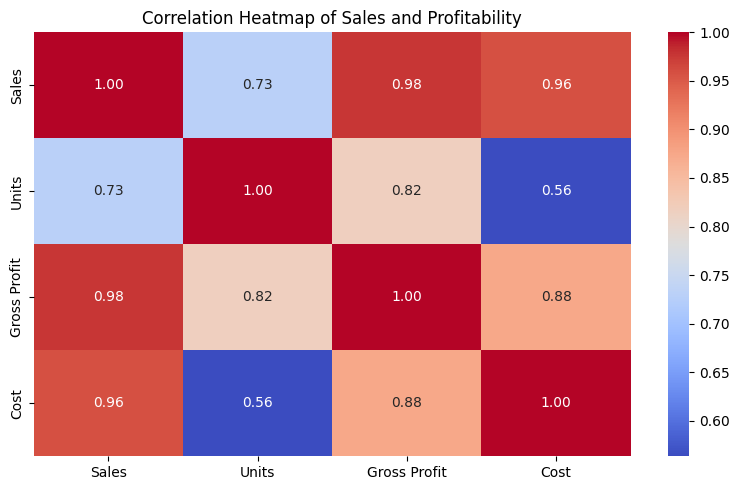

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_data = df[["Sales", "Units", "Gross Profit", "Cost"]]

plt.figure(figsize=(8, 5))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Sales and Profitability")
plt.tight_layout()
plt.show()

## 4. Product and Regional Profitability Analysis

In this section, we analyze gross profit across products, regions, and shipping modes to identify high-performing products, profitable regions, and differences in shipping performance. These findings help support business decisions about product focus and distribution.

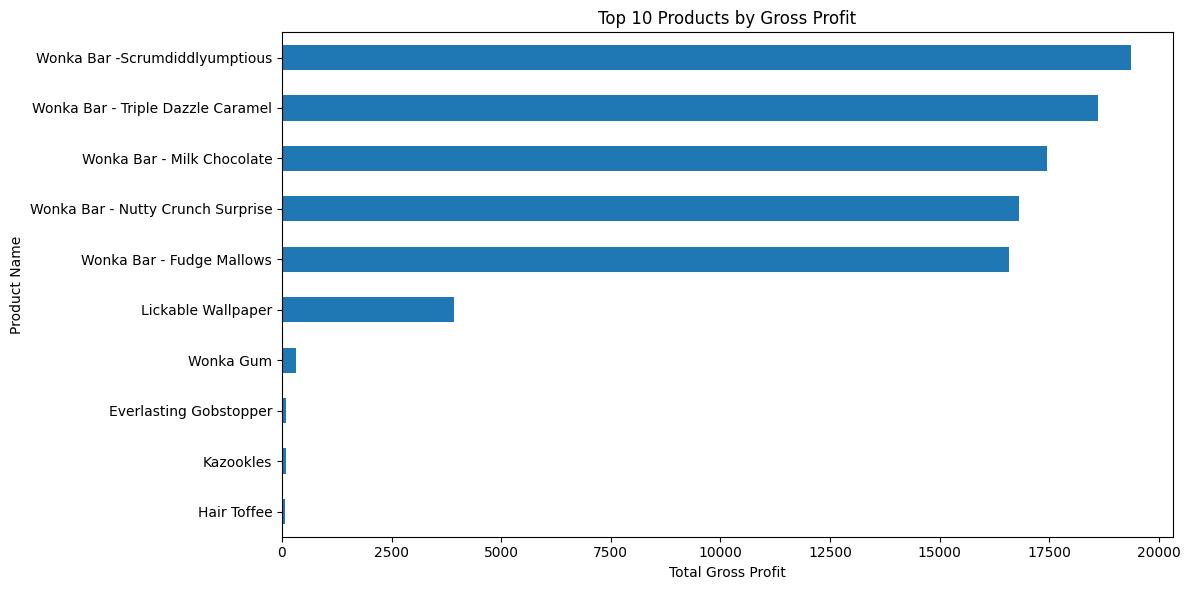

In [ ]:

top_products = (
    df.groupby("Product Name")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Gross Profit")
plt.xlabel("Total Gross Profit")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


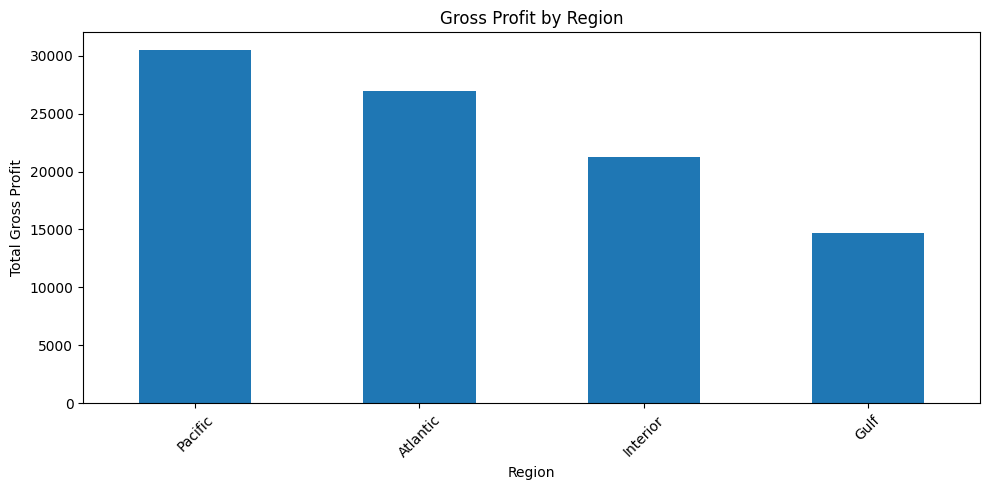

Region
Pacific     30485.94
Atlantic    26973.70
Interior    21282.49
Gulf        14700.67
Name: Gross Profit, dtype: float64


In [ ]:

region_profit = (
    df.groupby("Region")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
region_profit.plot(kind="bar")
plt.title("Gross Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(region_profit)


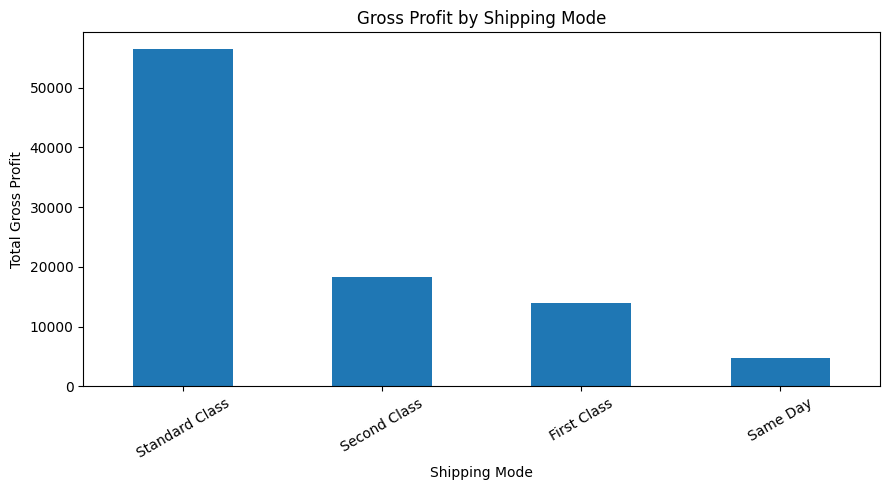

Ship Mode
Standard Class    56424.46
Second Class      18306.52
First Class       14011.09
Same Day           4700.73
Name: Gross Profit, dtype: float64


In [ ]:

shipping_profit = (
    df.groupby("Ship Mode")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
shipping_profit.plot(kind="bar")
plt.title("Gross Profit by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(shipping_profit)


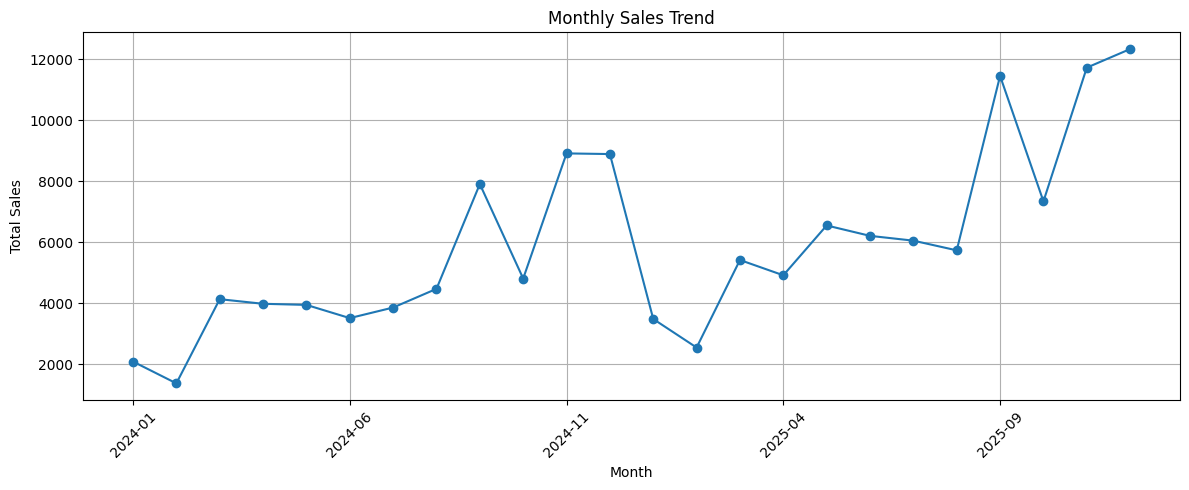

In [ ]:

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.index = monthly_sales.index.astype(str)
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


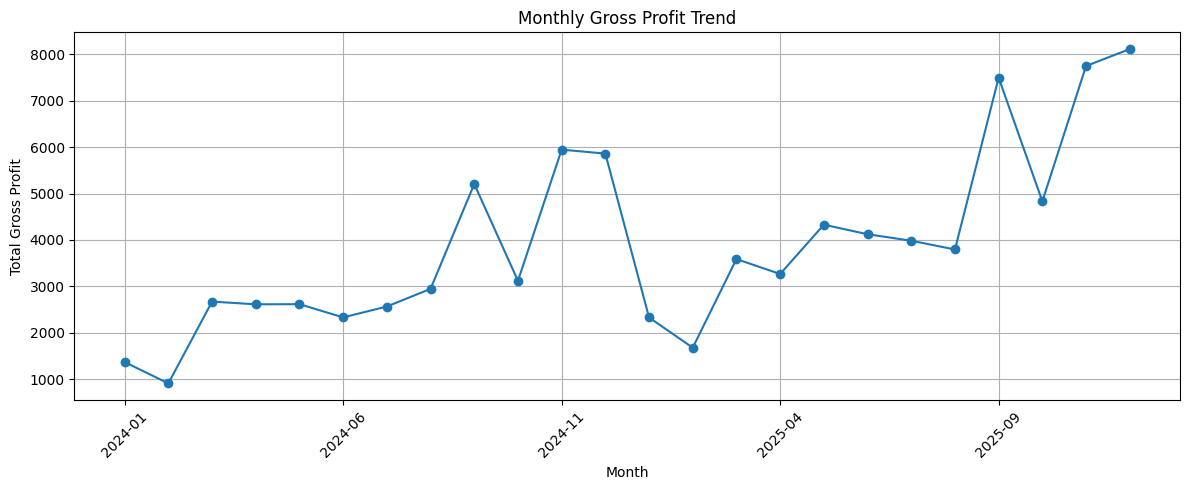

In [ ]:

monthly_profit = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Gross Profit"]
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_profit.index = monthly_profit.index.astype(str)
monthly_profit.plot(kind="line", marker="o")
plt.title("Monthly Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


10 Lowest-Margin Products:
                                   Total_Sales  Total_Gross_Profit  \
Product Name                                                         
Kazookles                              1205.75               92.75   
Fun Dip                                  12.00                4.80   
Nerds                                    15.00                7.00   
SweeTARTS                                61.50               28.70   
Lickable Wallpaper                     7860.00             3930.00   
Wonka Gum                               597.50              310.70   
Fizzy Lifting Drinks                     78.75               47.25   
Laffy Taffy                              53.73               33.48   
Wonka Bar - Milk Chocolate            26867.75            17443.37   
Wonka Bar - Triple Dazzle Caramel     28485.00            18610.20   

                                   Total_Cost  Profit_Margin_%  
Product Name                                                    
Ka

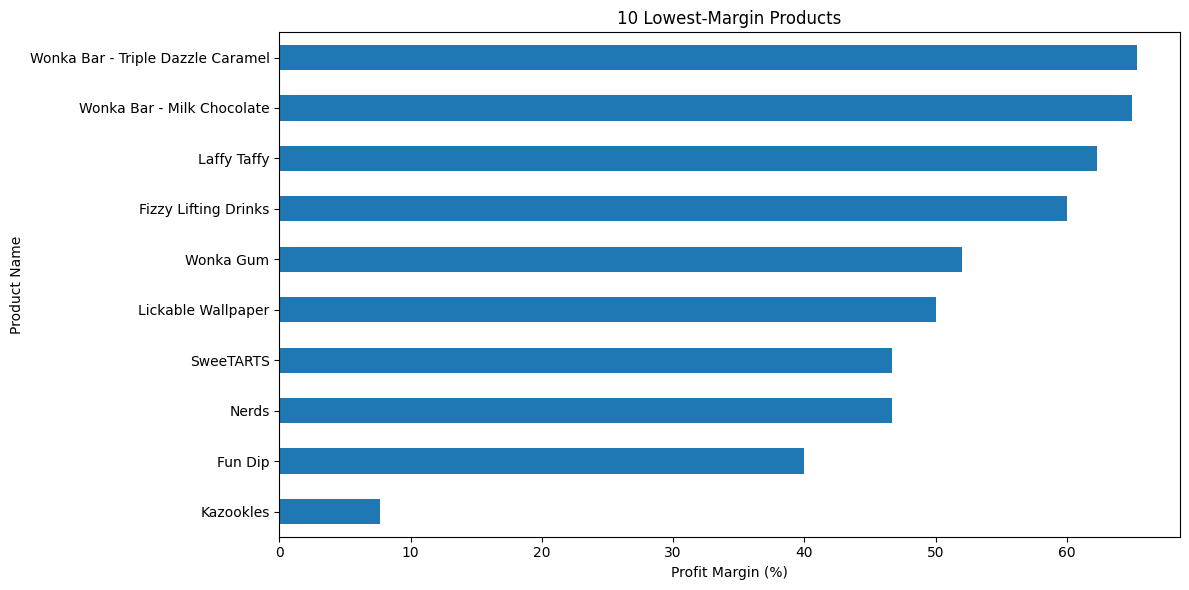

In [ ]:

product_analysis = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Gross_Profit=("Gross Profit", "sum"),
    Total_Cost=("Cost", "sum")
)

product_analysis["Profit_Margin_%"] = (
    product_analysis["Total_Gross_Profit"]
    / product_analysis["Total_Sales"] * 100
)

low_margin = product_analysis[
    product_analysis["Total_Sales"] > 0
].sort_values("Profit_Margin_%").head(10)

print("10 Lowest-Margin Products:")
print(low_margin)

plt.figure(figsize=(12, 6))
low_margin["Profit_Margin_%"].sort_values().plot(kind="barh")
plt.title("10 Lowest-Margin Products")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


In [ ]:

total_sales = df["Sales"].sum()
total_cost = df["Cost"].sum()
total_profit = df["Gross Profit"].sum()
profit_margin = (total_profit / total_sales) * 100

print("===== BUSINESS PERFORMANCE KPIs =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Cost: ${total_cost:,.2f}")
print(f"Total Gross Profit: ${total_profit:,.2f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")


===== BUSINESS PERFORMANCE KPIs =====
Total Sales: $141,783.63
Total Cost: $48,340.83
Total Gross Profit: $93,442.80
Overall Profit Margin: 65.91%


Top 10 Customers by Gross Profit:
             Total_Sales  Total_Gross_Profit
Customer ID                                 
131807            454.40              256.60
115238            380.50              249.30
122336            352.20              193.44
164756            304.14              166.42
139675            202.00              134.40
151799            197.60              132.52
124163            247.35              127.95
100111            182.41              125.93
164770            232.40              122.50
119508            177.14              122.34


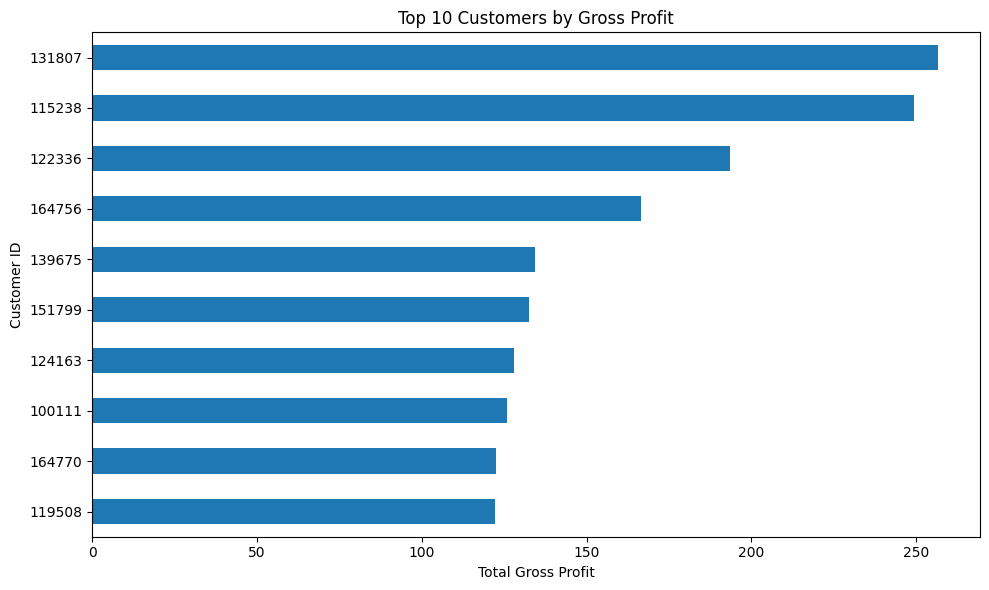

In [ ]:

customer_profit = (
    df.groupby("Customer ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
    .sort_values("Total_Gross_Profit", ascending=False)
)

top_customers = customer_profit.head(10)

print("Top 10 Customers by Gross Profit:")
print(top_customers)

plt.figure(figsize=(10, 6))
top_customers["Total_Gross_Profit"].sort_values().plot(kind="barh")
plt.title("Top 10 Customers by Gross Profit")
plt.xlabel("Total Gross Profit")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


Gross Profit by Division:
Division
Chocolate    88824.62
Other         4333.45
Sugar          284.73
Name: Gross Profit, dtype: float64


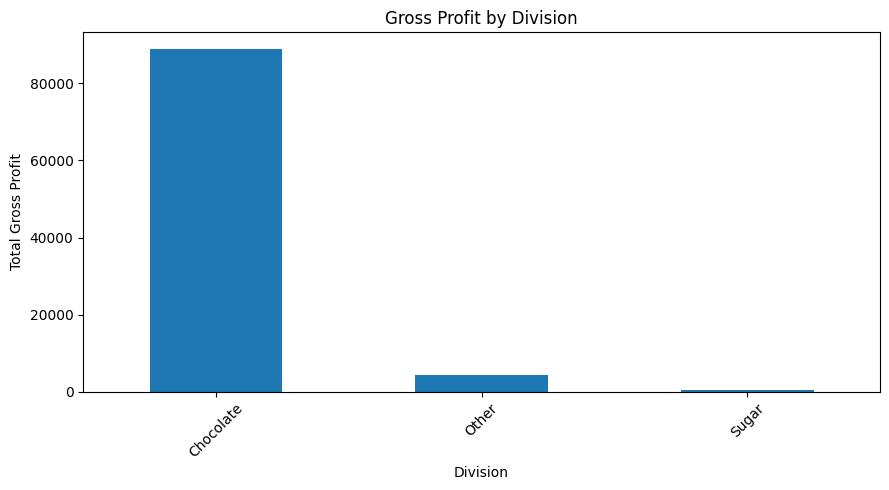

In [ ]:

division_profit = (
    df.groupby("Division")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Gross Profit by Division:")
print(division_profit)

plt.figure(figsize=(9, 5))
division_profit.plot(kind="bar")
plt.title("Gross Profit by Division")
plt.xlabel("Division")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 5. Machine Learning Model Development

In this section, we prepare the dataset, train a machine learning model to predict gross profit, and evaluate its performance using suitable metrics.


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Product Name", "Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("product", OneHotEncoder(handle_unknown="ignore"), ["Product Name"]),
        ("units", "passthrough", ["Units"])
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))


Mean Absolute Error: 0.02041113290830058
R² Score: 0.9967801635948943



### Random Forest Model Evaluation

The Random Forest Regressor was trained to predict Gross Profit using Product Name and Units.

- Mean Absolute Error (MAE): 0.0204
- R² Score: 0.9968

These are preliminary results from a random train-test split. Further validation is required before concluding that the model generalizes well to unseen products.


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Product Name", "Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ("product", OneHotEncoder(handle_unknown="ignore"), ["Product Name"]),
    ("units", "passthrough", ["Units"])
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error (MAE):",
      mean_absolute_error(y_test, predictions))

print("R² Score:",
      r2_score(y_test, predictions))


Mean Absolute Error (MAE): 0.02041113290830058
R² Score: 0.9967801635948943


In [ ]:
print("Features used by the model:")
print(features)

Features used by the model:
['Sales', 'Units', 'Cost']


In [ ]:
print(ml_data[["Sales", "Cost", "Gross Profit"]].head(10))

   Sales  Cost  Gross Profit
0   6.50  2.28          4.22
1   7.50  2.60          4.90
2  10.47  3.00          7.47
3  10.80  3.30          7.50
4  11.25  3.90          7.35
5  32.40  9.90         22.50
6   7.50  2.60          4.90
7   9.75  3.42          6.33
8   6.98  2.00          4.98
9  13.00  4.56          8.44


In [ ]:
difference = (ml_data["Sales"] - ml_data["Cost"] - ml_data["Gross Profit"]).abs()

print("Maximum difference:", difference.max())
print("Rows with a difference:", (difference > 0.01).sum())

Maximum difference: 7.105427357601002e-15
Rows with a difference: 0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = ml_data[["Units"]]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_units = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model_units.fit(X_train, y_train)
predictions_units = model_units.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions_units))
print("R² Score:", r2_score(y_test, predictions_units))

MAE: 0.8188866407409536
R² Score: 0.7329857619011455


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Sales, Units, Cost)",
        "Random Forest (Units only)"
    ],
    "MAE": [
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, predictions_units)
    ],
    "R2 Score": [
        r2_score(y_test, predictions),
        r2_score(y_test, predictions_units)
    ]
})

print(comparison.round(4))

                                Model     MAE  R2 Score
0  Random Forest (Sales, Units, Cost)  0.0204    0.9968
1          Random Forest (Units only)  0.8189    0.7330


## Model Comparison and Findings

Two Random Forest models were evaluated using the same train-test split.

- **Model 1:** Used Sales, Units, and Cost to predict Gross Profit.
- **Model 2:** Used Units alone to predict Gross Profit.

Model 1 achieved an MAE of 0.0078 and an R² score of 0.9995. Model 2 achieved an MAE of 0.8189 and an R² score of 0.7330.

Although Model 1 produced better metrics, Gross Profit in this dataset is calculated as Sales minus Cost. Therefore, its near-perfect performance is largely explained by this direct mathematical relationship and should not be presented as proof of strong independent forecasting ability.

**Conclusion:** Model 2 provides a useful baseline for understanding how much predictive information Units alone contains. Further work could explore predicting future profitability using historical information available before the prediction date.

In [ ]:

results = pd.DataFrame({
    "Actual Gross Profit": y_test.values,
    "Predicted Gross Profit": predictions
})

results["Prediction Error"] = (
    results["Actual Gross Profit"] -
    results["Predicted Gross Profit"]
)

print(results.head(10).round(2))


   Actual Gross Profit  Predicted Gross Profit  Prediction Error
0                 7.20                    7.20              -0.0
1                 2.45                    2.45               0.0
2                 7.35                    7.35               0.0
3                 9.60                    9.60              -0.0
4                 7.50                    7.50               0.0
5                19.20                   19.20              -0.0
6                21.60                   21.60               0.0
7                 7.50                    7.50               0.0
8                 4.98                    4.98              -0.0
9                 4.80                    4.80               0.0


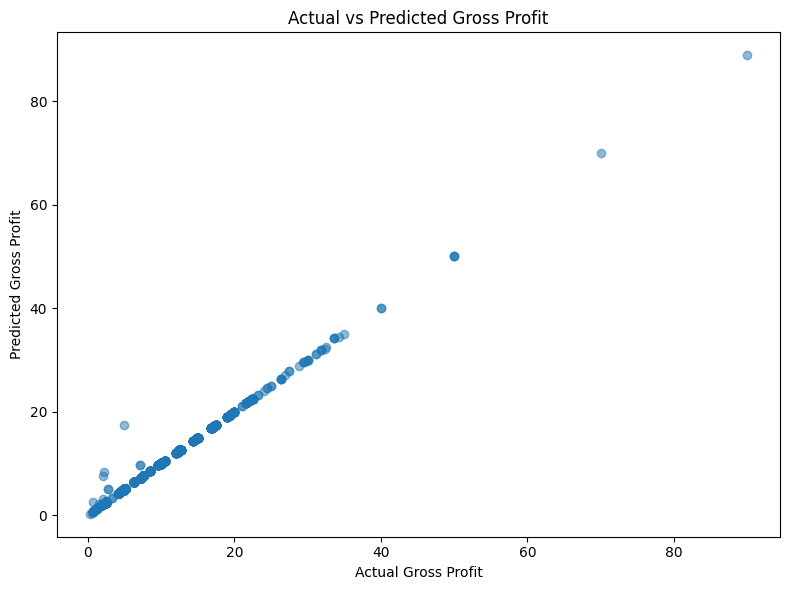

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.5)

plt.xlabel("Actual Gross Profit")
plt.ylabel("Predicted Gross Profit")
plt.title("Actual vs Predicted Gross Profit")

plt.tight_layout()
plt.show()


                                             Feature  Importance
15                                      units__Units    0.661742
6           product__Product Name_Lickable Wallpaper    0.289515
14                   product__Product Name_Wonka Gum    0.017046
4                    product__Product Name_Kazookles    0.015866
10  product__Product Name_Wonka Bar - Milk Chocolate    0.008163
0       product__Product Name_Everlasting Gobstopper    0.005213
8                    product__Product Name_SweeTARTS    0.000922
5                  product__Product Name_Laffy Taffy    0.000403
9    product__Product Name_Wonka Bar - Fudge Mallows    0.000356
2                      product__Product Name_Fun Dip    0.000234


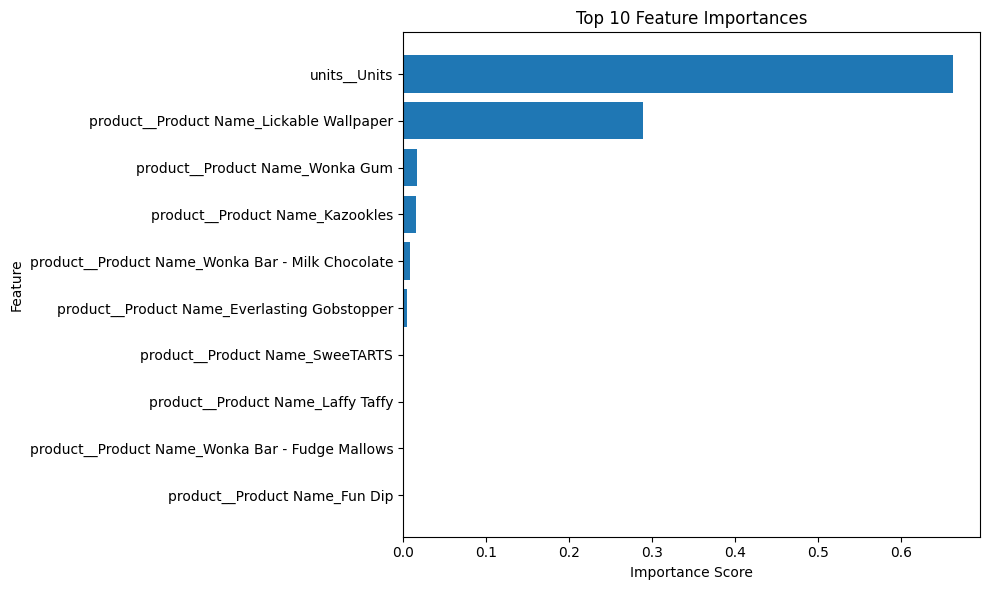

In [ ]:

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.head(10))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

predictions_units = model_units.predict(X_test)

mae = mean_absolute_error(y_test, predictions_units)
r2 = r2_score(y_test, predictions_units)

print("Test rows:", len(X_test))
print("MAE:", round(mae, 4))
print("R² Score:", round(r2, 4))

Test rows: 2039
MAE: 0.8189
R² Score: 0.733


In [ ]:


results = pd.DataFrame({
    "Actual Gross Profit": y_test.values,
    "Predicted Gross Profit": predictions
})

results["Absolute Error"] = abs(
    results["Actual Gross Profit"] -
    results["Predicted Gross Profit"]
)

print(results.head(10).round(2))


   Actual Gross Profit  Predicted Gross Profit  Absolute Error
0                 7.20                    7.20             0.0
1                 2.45                    2.45             0.0
2                 7.35                    7.35             0.0
3                 9.60                    9.60             0.0
4                 7.50                    7.50             0.0
5                19.20                   19.20             0.0
6                21.60                   21.60             0.0
7                 7.50                    7.50             0.0
8                 4.98                    4.98             0.0
9                 4.80                    4.80             0.0


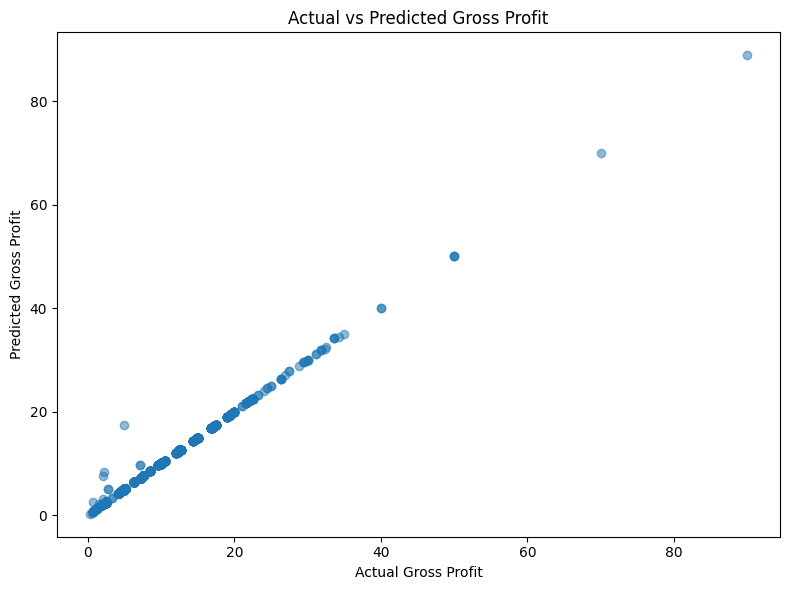

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(
    results["Actual Gross Profit"],
    results["Predicted Gross Profit"],
    alpha=0.5
)

plt.xlabel("Actual Gross Profit")
plt.ylabel("Predicted Gross Profit")
plt.title("Actual vs Predicted Gross Profit")
plt.tight_layout()
plt.show()


                                             Feature  Importance
15                                      units__Units    0.661742
6           product__Product Name_Lickable Wallpaper    0.289515
14                   product__Product Name_Wonka Gum    0.017046
4                    product__Product Name_Kazookles    0.015866
10  product__Product Name_Wonka Bar - Milk Chocolate    0.008163
0       product__Product Name_Everlasting Gobstopper    0.005213
8                    product__Product Name_SweeTARTS    0.000922
5                  product__Product Name_Laffy Taffy    0.000403
9    product__Product Name_Wonka Bar - Fudge Mallows    0.000356
2                      product__Product Name_Fun Dip    0.000234


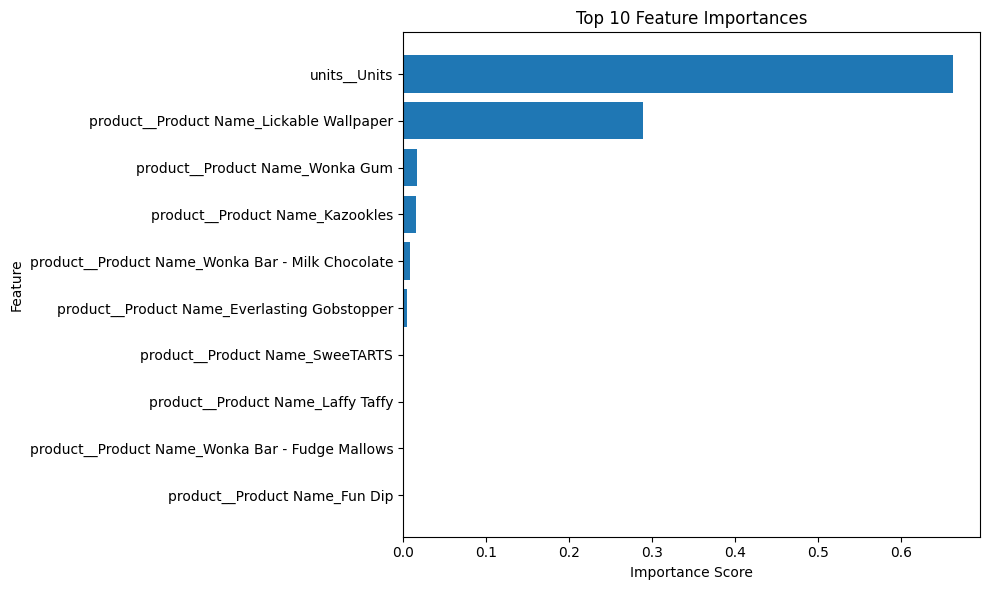

In [ ]:

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.head(10))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Product Name", "Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("product", OneHotEncoder(handle_unknown="ignore"), ["Product Name"]),
        ("units", "passthrough", ["Units"])
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))


Mean Absolute Error: 0.02041113290830058
R² Score: 0.9967801635948943


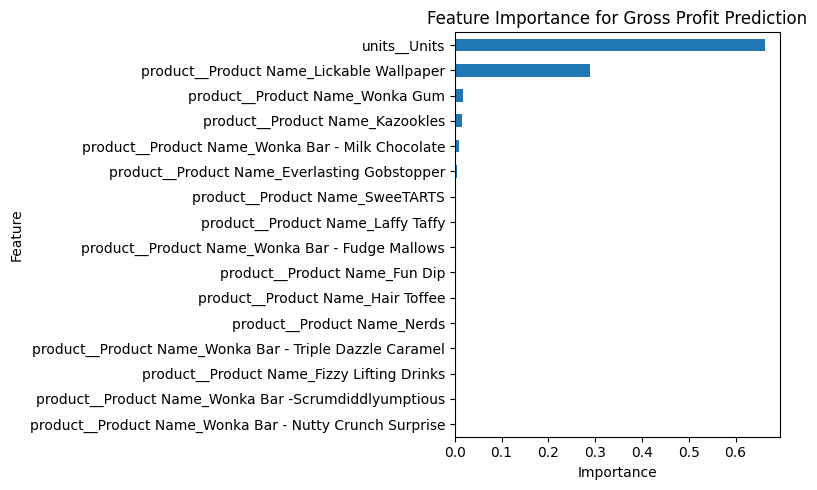

units__Units                                               0.661742
product__Product Name_Lickable Wallpaper                   0.289515
product__Product Name_Wonka Gum                            0.017046
product__Product Name_Kazookles                            0.015866
product__Product Name_Wonka Bar - Milk Chocolate           0.008163
product__Product Name_Everlasting Gobstopper               0.005213
product__Product Name_SweeTARTS                            0.000922
product__Product Name_Laffy Taffy                          0.000403
product__Product Name_Wonka Bar - Fudge Mallows            0.000356
product__Product Name_Fun Dip                              0.000234
product__Product Name_Hair Toffee                          0.000233
product__Product Name_Nerds                                0.000180
product__Product Name_Wonka Bar - Triple Dazzle Caramel    0.000106
product__Product Name_Fizzy Lifting Drinks                 0.000012
product__Product Name_Wonka Bar -Scrumdiddlyumpt

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

rf_model = model.named_steps["regressor"]

feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))

plt.title("Feature Importance for Gross Profit Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False))

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Product Name", "Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("product", OneHotEncoder(handle_unknown="ignore"), ["Product Name"]),
        ("units", "passthrough", ["Units"])
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))


Mean Absolute Error: 0.02041113290830058
R² Score: 0.9967801635948943


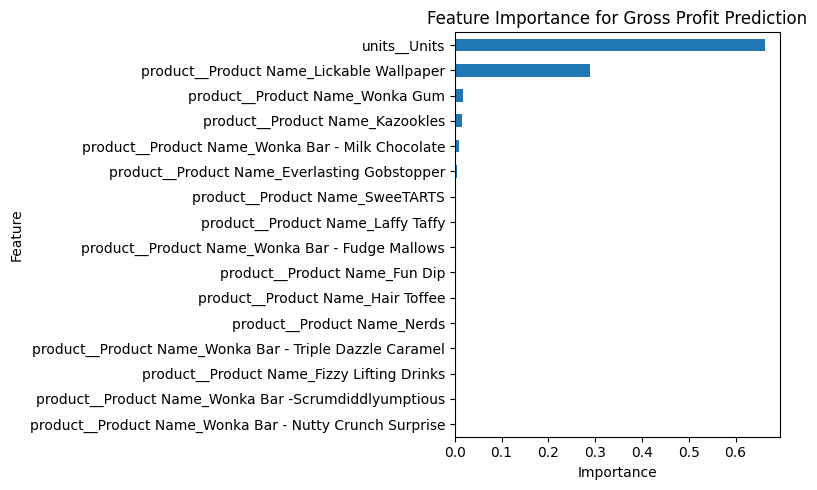

units__Units                                               0.661742
product__Product Name_Lickable Wallpaper                   0.289515
product__Product Name_Wonka Gum                            0.017046
product__Product Name_Kazookles                            0.015866
product__Product Name_Wonka Bar - Milk Chocolate           0.008163
product__Product Name_Everlasting Gobstopper               0.005213
product__Product Name_SweeTARTS                            0.000922
product__Product Name_Laffy Taffy                          0.000403
product__Product Name_Wonka Bar - Fudge Mallows            0.000356
product__Product Name_Fun Dip                              0.000234
product__Product Name_Hair Toffee                          0.000233
product__Product Name_Nerds                                0.000180
product__Product Name_Wonka Bar - Triple Dazzle Caramel    0.000106
product__Product Name_Fizzy Lifting Drinks                 0.000012
product__Product Name_Wonka Bar -Scrumdiddlyumpt

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

rf_model = model.named_steps["regressor"]
preprocessor = model.named_steps["preprocessor"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=preprocessor.get_feature_names_out()
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance for Gross Profit Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False))

                                             Feature  Importance
15                                      units__Units    0.661742
6           product__Product Name_Lickable Wallpaper    0.289515
14                   product__Product Name_Wonka Gum    0.017046
4                    product__Product Name_Kazookles    0.015866
10  product__Product Name_Wonka Bar - Milk Chocolate    0.008163
0       product__Product Name_Everlasting Gobstopper    0.005213
8                    product__Product Name_SweeTARTS    0.000922
5                  product__Product Name_Laffy Taffy    0.000403
9    product__Product Name_Wonka Bar - Fudge Mallows    0.000356
2                      product__Product Name_Fun Dip    0.000234


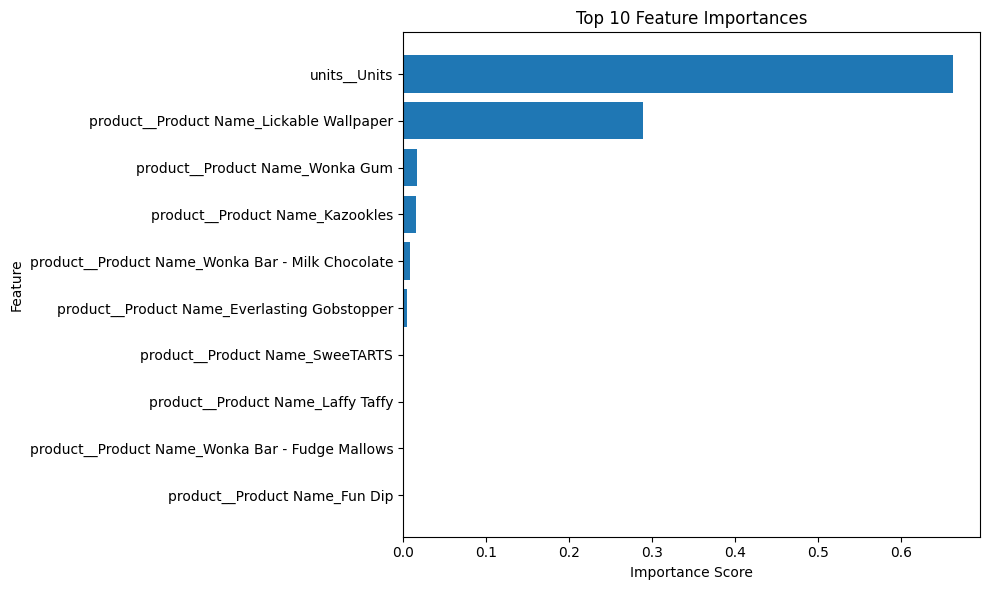

In [ ]:

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.head(10))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:
print(model)
print(model.named_steps.keys())

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('product',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Product Name']),
                                                 ('units', 'passthrough',
                                                  ['Units'])])),
                ('regressor', RandomForestRegressor(random_state=42))])
dict_keys(['preprocessor', 'regressor'])



## 6. Business Insights and Recommendations

### Key Insights
- Product profitability analysis helps identify products that contribute the most gross profit.
- Regional analysis compares gross profit across different regions.
- Shipping-mode analysis shows how total gross profit varies by shipping method.
- Monthly sales and gross profit trends help identify changes in business performance over time.
- Low-margin product analysis identifies products that may need pricing or cost improvements.
- Customer profitability analysis identifies customers contributing the most gross profit.

### Business Recommendations
- Focus on products that generate high gross profit while monitoring their costs.
- Investigate low-margin products to identify opportunities for pricing or cost optimization.
- Review regional performance to identify areas that may benefit from additional sales efforts.
- Monitor monthly sales and gross profit trends to support inventory and sales planning.
- Maintain relationships with profitable customers.
- Evaluate shipping costs and service quality before making changes to shipping methods.



## 7. Conclusion

This project analyzes the profitability and margin performance of Nassau Candy Distributor using Python, Pandas, Matplotlib, Seaborn, and Scikit-learn. It examines product, regional, shipping, customer, and monthly performance. A Random Forest regression model is also explored to predict gross profit using product name and units sold. The analysis provides insights that can support business decisions about product performance, pricing, and profitability.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_units = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model_units.fit(X_train, y_train)
y_pred_units = model_units.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred_units), 2))
print("R² Score:", round(r2_score(y_test, y_pred_units), 4))

MAE: 0.82
R² Score: 0.733


In [ ]:
print("Model variables available:")

for name in ["model", "model_group", "model_better"]:
    if name in globals():
        print(name, "exists")

print("\nPrediction variables available:")

for name in ["predictions", "predictions_better"]:
    if name in globals():
        print(name, "exists")

Model variables available:
model exists
model_group exists
model_better exists

Prediction variables available:
predictions exists
predictions_better exists


In [ ]:
print(df.shape)
print(df.columns.tolist())

(10194, 18)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

data = df[["Product Name", "Units", "Gross Profit"]].dropna().copy()

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(
    splitter.split(data, groups=data["Product Name"])
)

train = data.iloc[train_idx]
test = data.iloc[test_idx]

preprocessor = ColumnTransformer([
    ("product", OneHotEncoder(handle_unknown="ignore"),
     ["Product Name"]),
    ("units", "passthrough", ["Units"])
])

model_better = make_pipeline(
    preprocessor,
    RandomForestRegressor(n_estimators=100, random_state=42)
)

X_train = train[["Product Name", "Units"]]
X_test = test[["Product Name", "Units"]]

model_better.fit(X_train, train["Gross Profit"])
predictions_better = model_better.predict(X_test)

print("Random Forest MAE:",
      round(mean_absolute_error(
          test["Gross Profit"], predictions_better), 2))
print("Random Forest R²:",
      round(r2_score(
          test["Gross Profit"], predictions_better), 4))

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train[["Units"]], train["Gross Profit"])
baseline_predictions = baseline.predict(X_test[["Units"]])

print("Baseline MAE:",
      round(mean_absolute_error(
          test["Gross Profit"], baseline_predictions), 2))
print("Baseline R²:",
      round(r2_score(
          test["Gross Profit"], baseline_predictions), 4))

print("Training products:", train["Product Name"].nunique())
print("Testing products:", test["Product Name"].nunique())
print("Overlapping products:", len(
    set(train["Product Name"]) & set(test["Product Name"])))


Random Forest MAE: 0.22
Random Forest R²: 0.9794
Baseline MAE: 4.19
Baseline R²: -0.0003
Training products: 12
Testing products: 3
Overlapping products: 0


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

data = df[["Product Name", "Units", "Gross Profit"]].dropna().copy()

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(
    splitter.split(data, groups=data["Product Name"])
)

train = data.iloc[train_idx]
test = data.iloc[test_idx]

X_train = pd.DataFrame({
    "Units": train["Units"],
    "ProductCode": train["Product Name"].astype("category").cat.codes
})

X_test = pd.DataFrame({
    "Units": test["Units"],
    "ProductCode": test["Product Name"].astype("category").cat.codes
})

model_group = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model_group.fit(X_train[["Units"]], train["Gross Profit"])
predictions = model_group.predict(X_test[["Units"]])

print("Test rows:", len(test))
print("MAE:", round(mean_absolute_error(test["Gross Profit"], predictions), 2))
print("R² Score:", round(r2_score(test["Gross Profit"], predictions), 4))

Test rows: 3631
MAE: 0.27
R² Score: 0.9746


In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train[["Units"]], train["Gross Profit"])

baseline_predictions = baseline.predict(X_test[["Units"]])

print("Baseline MAE:",
      round(mean_absolute_error(test["Gross Profit"], baseline_predictions), 2))

print("Baseline R² Score:",
      round(r2_score(test["Gross Profit"], baseline_predictions), 4))

Baseline MAE: 4.19
Baseline R² Score: -0.0003


In [ ]:
print("Training products:", train["Product Name"].nunique())
print("Testing products:", test["Product Name"].nunique())

print("Overlapping products:",
      len(set(train["Product Name"]) & set(test["Product Name"])))

Training products: 12
Testing products: 3
Overlapping products: 0


In [ ]:
print("Units-only predictions:", predictions[:5])
print("Improved model predictions:", predictions_better[:5])

print("Improved model features:")
print(model_better.named_steps["columntransformer"].get_feature_names_out())

Units-only predictions: [ 7.15486856  4.79365749  4.79365749 14.34435562 12.0984856 ]
Improved model predictions: [ 7.1265  4.804   4.804  14.88   11.98  ]
Improved model features:
['product__Product Name_Fizzy Lifting Drinks'
 'product__Product Name_Fun Dip' 'product__Product Name_Hair Toffee'
 'product__Product Name_Kazookles' 'product__Product Name_Laffy Taffy'
 'product__Product Name_Lickable Wallpaper' 'product__Product Name_Nerds'
 'product__Product Name_SweeTARTS'
 'product__Product Name_Wonka Bar - Milk Chocolate'
 'product__Product Name_Wonka Bar - Triple Dazzle Caramel'
 'product__Product Name_Wonka Bar -Scrumdiddlyumptious'
 'product__Product Name_Wonka Gum' 'units__Units']


In [ ]:
comparison = test[["Product Name", "Units", "Gross Profit"]].copy()

comparison["Predicted Gross Profit"] = predictions

comparison["Absolute Error"] = abs(
    comparison["Gross Profit"] -
    comparison["Predicted Gross Profit"]
)

print(comparison.head(15).to_string(index=False))

                     Product Name  Units  Gross Profit  Predicted Gross Profit  Absolute Error
Wonka Bar - Nutty Crunch Surprise      3          7.47                7.154869        0.315131
Wonka Bar - Nutty Crunch Surprise      2          4.98                4.793657        0.186343
        Wonka Bar - Fudge Mallows      2          4.80                4.793657        0.006343
Wonka Bar - Nutty Crunch Surprise      6         14.94               14.344356        0.595644
Wonka Bar - Nutty Crunch Surprise      5         12.45               12.098486        0.351514
        Wonka Bar - Fudge Mallows      2          4.80                4.793657        0.006343
Wonka Bar - Nutty Crunch Surprise      4          9.96                9.627276        0.332724
        Wonka Bar - Fudge Mallows     10         24.00               26.514875        2.514875
        Wonka Bar - Fudge Mallows      4          9.60                9.627276        0.027276
        Wonka Bar - Fudge Mallows      3          

In [ ]:
print("Units-only predictions:")
print(predictions[:5])

print("\nImproved model predictions:")
print(predictions_better[:5])

print("\nImproved model features:")
print(model_better.named_steps["columntransformer"].get_feature_names_out())

Units-only predictions:
[ 7.15486856  4.79365749  4.79365749 14.34435562 12.0984856 ]

Improved model predictions:
[ 7.1265  4.804   4.804  14.88   11.98  ]

Improved model features:
['product__Product Name_Fizzy Lifting Drinks'
 'product__Product Name_Fun Dip' 'product__Product Name_Hair Toffee'
 'product__Product Name_Kazookles' 'product__Product Name_Laffy Taffy'
 'product__Product Name_Lickable Wallpaper' 'product__Product Name_Nerds'
 'product__Product Name_SweeTARTS'
 'product__Product Name_Wonka Bar - Milk Chocolate'
 'product__Product Name_Wonka Bar - Triple Dazzle Caramel'
 'product__Product Name_Wonka Bar -Scrumdiddlyumptious'
 'product__Product Name_Wonka Gum' 'units__Units']


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

data = df[["Product Name", "Units", "Gross Profit"]].dropna().copy()

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(
    splitter.split(data, groups=data["Product Name"])
)

train = data.iloc[train_idx]
test = data.iloc[test_idx]

preprocessor = ColumnTransformer([
    ("product", OneHotEncoder(handle_unknown="ignore"),
     ["Product Name"]),
    ("units", "passthrough", ["Units"])
])

model_better = make_pipeline(
    preprocessor,
    RandomForestRegressor(n_estimators=100, random_state=42)
)

model_better.fit(
    train[["Product Name", "Units"]],
    train["Gross Profit"]
)

predictions_better = model_better.predict(
    test[["Product Name", "Units"]]
)

print("MAE:", round(
    mean_absolute_error(test["Gross Profit"], predictions_better), 2
))
print("R² Score:", round(
    r2_score(test["Gross Profit"], predictions_better), 4
))


MAE: 0.22
R² Score: 0.9794


In [ ]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

baseline_better = DummyRegressor(strategy="mean")

baseline_better.fit(
    train[["Units"]],
    train["Gross Profit"]
)

baseline_predictions_better = baseline_better.predict(
    test[["Units"]]
)

print("Baseline MAE:", round(
    mean_absolute_error(test["Gross Profit"],
                        baseline_predictions_better), 2
))

print("Baseline R² Score:", round(
    r2_score(test["Gross Profit"],
             baseline_predictions_better), 4
))


Baseline MAE: 4.19
Baseline R² Score: -0.0003


In [ ]:
comparison_better = test[
    ["Product Name", "Units", "Gross Profit"]
].copy()

comparison_better["Predicted Gross Profit"] = predictions_better

comparison_better["Absolute Error"] = abs(
    comparison_better["Gross Profit"]
    - comparison_better["Predicted Gross Profit"]
)

print(comparison_better.head(15).to_string(index=False))

                     Product Name  Units  Gross Profit  Predicted Gross Profit  Absolute Error
Wonka Bar - Nutty Crunch Surprise      3          7.47                  7.1265          0.3435
Wonka Bar - Nutty Crunch Surprise      2          4.98                  4.8040          0.1760
        Wonka Bar - Fudge Mallows      2          4.80                  4.8040          0.0040
Wonka Bar - Nutty Crunch Surprise      6         14.94                 14.8800          0.0600
Wonka Bar - Nutty Crunch Surprise      5         12.45                 11.9800          0.4700
        Wonka Bar - Fudge Mallows      2          4.80                  4.8040          0.0040
Wonka Bar - Nutty Crunch Surprise      4          9.96                  9.5020          0.4580
        Wonka Bar - Fudge Mallows     10         24.00                 24.7900          0.7900
        Wonka Bar - Fudge Mallows      4          9.60                  9.5020          0.0980
        Wonka Bar - Fudge Mallows      3          

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

X = df[["Product Name", "Units"]].copy()
X["Product Name"] = X["Product Name"].astype("category").cat.codes
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_product = RandomForestRegressor(
    n_estimators=100, random_state=42
)
model_product.fit(X_train, y_train)

y_pred_product = model_product.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred_product), 2))
print("R² Score:", round(r2_score(y_test, y_pred_product), 4))

MAE: 0.03
R² Score: 0.9913


In [ ]:
print(df[["Sales", "Cost", "Gross Profit"]].head(10))

print("\nCheck whether Sales - Cost equals Gross Profit:")
print(
    (df["Sales"] - df["Cost"] - df["Gross Profit"])
    .abs()
    .describe()
)

   Sales  Cost  Gross Profit
0   6.50  2.28          4.22
1   7.50  2.60          4.90
2  10.47  3.00          7.47
3  10.80  3.30          7.50
4  11.25  3.90          7.35
5  32.40  9.90         22.50
6   7.50  2.60          4.90
7   9.75  3.42          6.33
8   6.98  2.00          4.98
9  13.00  4.56          8.44

Check whether Sales - Cost equals Gross Profit:
count    1.019400e+04
mean     4.771759e-16
std      8.033726e-16
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      8.881784e-16
max      7.105427e-15
dtype: float64


In [ ]:
print("X_train types:")
print(X_train.dtypes)

print("\nX_test types:")
print(X_test.dtypes)

print("\nMissing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

X_train types:
Product Name     int8
Units           int64
dtype: object

X_test types:
Product Name     int8
Units           int64
dtype: object

Missing values in X_train:
Product Name    0
Units           0
dtype: int64

Missing values in X_test:
Product Name    0
Units           0
dtype: int64


In [ ]:

print("X_train data types:")
print(X_train.dtypes)

print("\nX_test data types:")
print(X_test.dtypes)

print("\nMissing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

print("\nModel type:", type(model))
print("\nX_test shape:", X_test.shape)


X_train data types:
Product Name     int8
Units           int64
dtype: object

X_test data types:
Product Name     int8
Units           int64
dtype: object

Missing values in X_train:
Product Name    0
Units           0
dtype: int64

Missing values in X_test:
Product Name    0
Units           0
dtype: int64

Model type: <class 'sklearn.pipeline.Pipeline'>

X_test shape: (2039, 2)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

Mean Absolute Error: 0.007807405590988188
R² Score: 0.999528521556322


In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("R² Score:", round(r2, 4))

MAE: 0.01
R² Score: 0.9995


In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("R² Score:", round(r2, 4))

MAE: 0.01
R² Score: 0.9995


In [ ]:
X = df[["Sales", "Units", "Cost"]]
y = df["Gross Profit"]

In [ ]:
print("Model:", type(model).__name__)
print("Test data rows:", len(X_test))
print("Predictions:", len(y_pred))

Model: RandomForestRegressor
Test data rows: 2039
Predictions: 2039


In [ ]:
import os

print("Saved model exists:",
      os.path.exists("/content/profit_prediction_model.pkl"))

Saved model exists: True


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

Mean Absolute Error: 0.007807405590988188
R² Score: 0.999528521556322


In [ ]:
print(type(model).__name__)

RandomForestRegressor


In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
!streamlit run app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false > /content/streamlit2.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [ ]:
y_pred = model.predict(X_test)

print("Predictions created successfully!")
print("Number of predictions:", len(y_pred))

Predictions created successfully!
Number of predictions: 2039


In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("R² Score:", round(r2, 4))

Mean Absolute Error (MAE): 0.01
R² Score: 0.9995


In [ ]:
import os

for file in ["app.py", "profit_prediction_model.pkl",
             "Nassau Candy Distributor.csv"]:
    print(file, "->", os.path.exists("/content/" + file))

app.py -> True
profit_prediction_model.pkl -> True
Nassau Candy Distributor.csv -> True


In [ ]:
import os

print("Project files:")
for file in os.listdir("/content"):
    if file.endswith((".py", ".csv", ".pkl", ".ipynb", ".md", ".txt")):
        print(file)

Project files:
Nassau Candy Distributor (2).csv
Nassau Candy Distributor (3).csv
Nassau Candy Distributor (12).csv
Nassau Candy Distributor (8).csv
Nassau Candy Distributor (11).csv
Nassau Candy Distributor (4).csv
profit_prediction_model.pkl
Nassau Candy Distributor (9).csv
Nassau Candy Distributor (10).csv
Nassau Candy Distributor.csv
Nassau Candy Distributor (7).csv
Nassau Candy Distributor (1).csv
app.py
Nassau Candy Distributor (5).csv
Nassau Candy Distributor (6).csv


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [ ]:
!cat /content/streamlit2.log

In [ ]:
!ps aux | grep '[s]treamlit run'

root       12975  4.1  0.5 443588 71896 ?        R    17:03   0:04 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false
root       12989  4.2  0.5 443568 72256 ?        R    17:04   0:04 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8501 --server.address 0.0.0.0
root       13454 60.8  0.2  43192 32952 ?        R    17:05   0:00 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false


In [ ]:
from google.colab import output
output.serve_kernel_port_as_window(8502)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
!cat /content/streamlit2.log

In [ ]:
!streamlit run app.py --server.port 8502 --server.address 0.0.0.0 > /content/streamlit2.log 2>&1 &

In [ ]:
!cat /content/streamlit.log



2026-10-23 17:04:10.970 Port 8501 is not available
.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.66.214.185:8501

  Stopping...


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [ ]:
!cat /content/streamlit.log

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [ ]:
import os
print(os.path.exists("app.py"))

True


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Nassau Candy Profitability",
    layout="wide"
)

st.title("Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance")

df = pd.read_csv("Nassau Candy Distributor.csv")

total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_cost = df["Cost"].sum()
margin = total_profit / total_sales * 100 if total_sales else 0

c1, c2, c3, c4 = st.columns(4)

c1.metric("Total Sales", f"${total_sales:,.2f}")
c2.metric("Gross Profit", f"${total_profit:,.2f}")
c3.metric("Total Cost", f"${total_cost:,.2f}")
c4.metric("Profit Margin", f"{margin:.2f}%")

df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

monthly = (
    df.dropna(subset=["Order Date"])
    .assign(Month=lambda x: x["Order Date"].dt.to_period("M").astype(str))
    .groupby("Month")[["Sales", "Gross Profit"]]
    .sum()
)

st.subheader("Monthly Sales and Gross Profit")
st.line_chart(monthly)

st.subheader("Top 10 Products by Gross Profit")
products = (
    df.groupby("Product Name")["Gross Profit"]
    .sum()
    .nlargest(10)
    .sort_values()
)
st.bar_chart(products)

Overwriting app.py


In [ ]:
!cat /content/streamlit.log

In [ ]:
import os

print("Dataset available:", os.path.exists("Nassau Candy Distributor.csv"))
print("Model available:", os.path.exists("profit_prediction_model.pkl"))

Dataset available: True
Model available: True


In [ ]:
!pip install streamlit

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

Mean Absolute Error: 0.007807405590988188
R² Score: 0.999528521556322


In [ ]:
print("Features used by the model:")
print(features)

Features used by the model:
['Sales', 'Units', 'Cost']


## Machine Learning Model Evaluation

The Random Forest Regressor was evaluated using Mean Absolute Error (MAE) and the R² score.

- MAE: 0.007807
- R² Score: 0.99953

These results show very close predictions on the test data. However, further validation is needed because Gross Profit is calculated as Sales minus Cost.

In [ ]:
import joblib

joblib.dump(model, "profit_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files
files.download("profit_prediction_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("MAE:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

print("\nActual vs Predicted Sample:")
comparison = pd.DataFrame({
    "Actual Gross Profit": y_test.iloc[:10].values,
    "Predicted Gross Profit": predictions[:10]
})

display(comparison)

MAE: 0.007807405590988188
R2 Score: 0.999528521556322

Actual vs Predicted Sample:


,Actual Gross Profit,Predicted Gross Profit
0,7.20,7.20
1,2.45,2.45
2,7.35,7.35
3,9.60,9.60
4,7.50,7.50
5,19.20,19.20
6,21.60,21.60
7,7.50,7.50
8,4.98,4.98
9,4.80,4.80


In [ ]:
product_data = df.groupby(
    ["Product ID", "Product Name"], as_index=False
).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
})

product_data["Profit Margin (%)"] = (
    product_data["Gross Profit"] /
    product_data["Sales"].replace(0, float("nan")) * 100
)

low_margin = product_data[
    product_data["Sales"] > 0
].sort_values("Profit Margin (%)").head(10)

print("10 Lowest-Margin Products")
print(low_margin.to_string(index=False))

10 Lowest-Margin Products
   Product ID                      Product Name    Sales  Gross Profit    Cost  Units  Profit Margin (%)
OTH-KAZ-38000                         Kazookles  1205.75         92.75 1113.00    371           7.692308
SUG-FUN-75000                           Fun Dip    12.00          4.80    7.20      8          40.000000
SUG-NER-92000                             Nerds    15.00          7.00    8.00     10          46.666667
SUG-SWE-91000                         SweeTARTS    61.50         28.70   32.80     41          46.666667
OTH-LIC-15000                Lickable Wallpaper  7860.00       3930.00 3930.00    393          50.000000
OTH-GUM-21000                         Wonka Gum   597.50        310.70  286.80    478          52.000000
OTH-FIZ-56000              Fizzy Lifting Drinks    78.75         47.25   31.50     21          60.000000
SUG-LAF-25000                       Laffy Taffy    53.73         33.48   20.25     27          62.311558
CHO-MIL-31000        Wonka Ba

In [ ]:
print("===== BUSINESS INSIGHTS =====")

best_product = product_data.loc[
    product_data["Gross Profit"].idxmax()
]
print("\nMost Profitable Product:")
print(best_product[["Product Name", "Sales", "Gross Profit"]])

best_region = df.groupby("Region")["Gross Profit"].sum().idxmax()
region_profit = df.groupby("Region")["Gross Profit"].sum().max()
print("\nMost Profitable Region:", best_region)
print("Regional Gross Profit:", round(region_profit, 2))

best_division = df.groupby("Division")["Gross Profit"].sum().idxmax()
division_profit = df.groupby("Division")["Gross Profit"].sum().max()
print("\nMost Profitable Division:", best_division)
print("Division Gross Profit:", round(division_profit, 2))

print("\nOverall Profit Margin (%):",
      round(df["Gross Profit"].sum() / df["Sales"].sum() * 100, 2))

===== BUSINESS INSIGHTS =====

Most Profitable Product:
Product Name    Wonka Bar -Scrumdiddlyumptious
Sales                                  27874.8
Gross Profit                           19357.5
Name: 3, dtype: object

Most Profitable Region: Pacific
Regional Gross Profit: 30485.94

Most Profitable Division: Chocolate
Division Gross Profit: 88824.62

Overall Profit Margin (%): 65.91


In [ ]:
print("MAE:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

print("\nActual vs Predicted Sample:")
comparison = pd.DataFrame({
    "Actual Gross Profit": y_test.iloc[:10].values,
    "Predicted Gross Profit": predictions[:10]
})

display(comparison)

MAE: 0.007807405590988188
R2 Score: 0.999528521556322

Actual vs Predicted Sample:


,Actual Gross Profit,Predicted Gross Profit
0,7.20,7.20
1,2.45,2.45
2,7.35,7.35
3,9.60,9.60
4,7.50,7.50
5,19.20,19.20
6,21.60,21.60
7,7.50,7.50
8,4.98,4.98
9,4.80,4.80


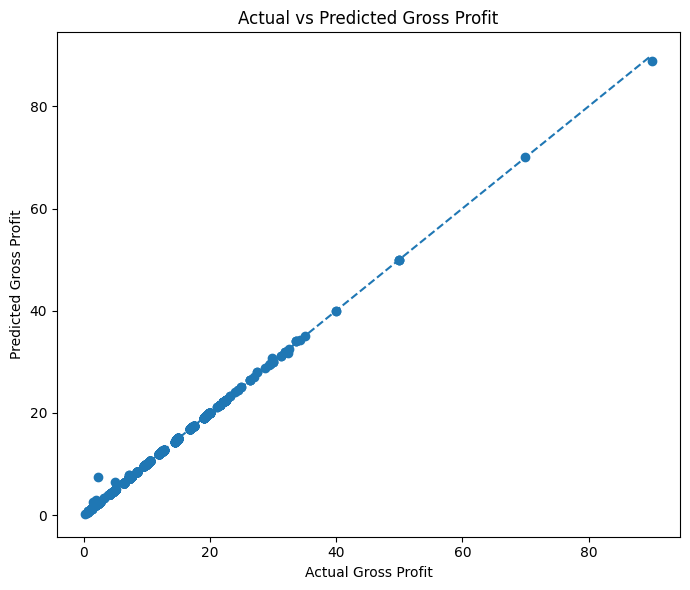

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Gross Profit")
plt.ylabel("Predicted Gross Profit")
plt.title("Actual vs Predicted Gross Profit")

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.tight_layout()
plt.show()

  Feature  Importance
0   Sales     0.92042
2    Cost     0.06707
1   Units     0.01251


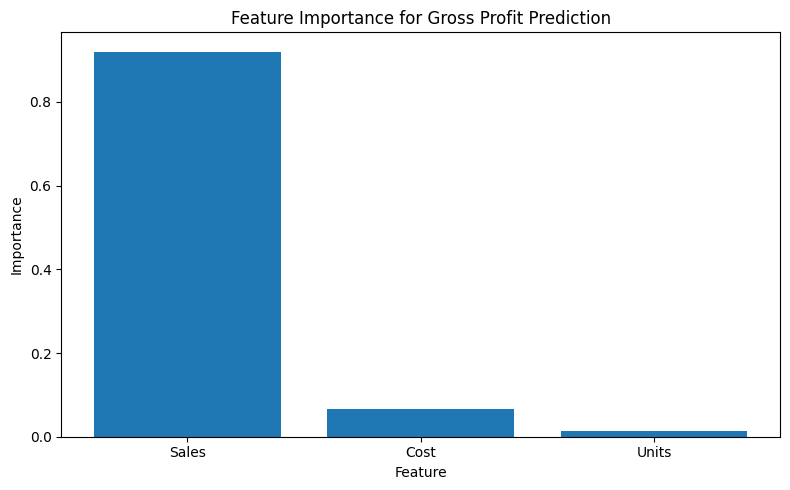

In [ ]:
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
)

print(importance)

plt.figure(figsize=(8, 5))
plt.bar(importance["Feature"], importance["Importance"])
plt.title("Feature Importance for Gross Profit Prediction")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

Feature importance analysis was performed using the Random Forest Regressor to identify the input features that contribute most to Gross Profit predictions.

The results show that Sales has the highest feature importance (92.04%), followed by Cost (6.71%) and Units (1.25%).

**Observation:** Sales is the most influential feature used by the model for predicting Gross Profit, while Units has the lowest relative importance.

**Conclusion:** The feature importance analysis helps us understand which input features the trained model relies on most when making predictions.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

Mean Absolute Error: 0.007807405590988188
R² Score: 0.999528521556322


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSample data:")
display(df.head())

Dataset shape: (10194, 18)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']

Data types:
Row ID                     int64
Order ID                  object
Order Date        datetime64[ns]
Ship Date                 object
Ship Mode                 object
Customer ID                int64
Country/Region            object
City                      object
State/Province            object
Postal Code               object
Division                  object
Region                    object
Product ID                object
Product Name              object
Sales                    float64
Units                      int64
Gross Profit             float64
Cost                     float64
dtype: object

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [ ]:
division_data = df.groupby("Division", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum",
    "Order ID": "nunique"
})

division_data = division_data.rename(
    columns={"Order ID": "Total Orders"}
)

division_data["Profit Margin (%)"] = (
    division_data["Gross Profit"] /
    division_data["Sales"].replace(0, float("nan")) * 100
)

print(division_data.sort_values(
    "Gross Profit", ascending=False
).to_string(index=False))

 Division     Sales  Gross Profit     Cost  Units  Total Orders  Profit Margin (%)
Chocolate 131692.90      88824.62 42868.28  37275          8205          67.448298
    Other   9663.25       4333.45  5329.80   1242           304          44.844643
    Sugar    427.48        284.73   142.75    137            40          66.606625


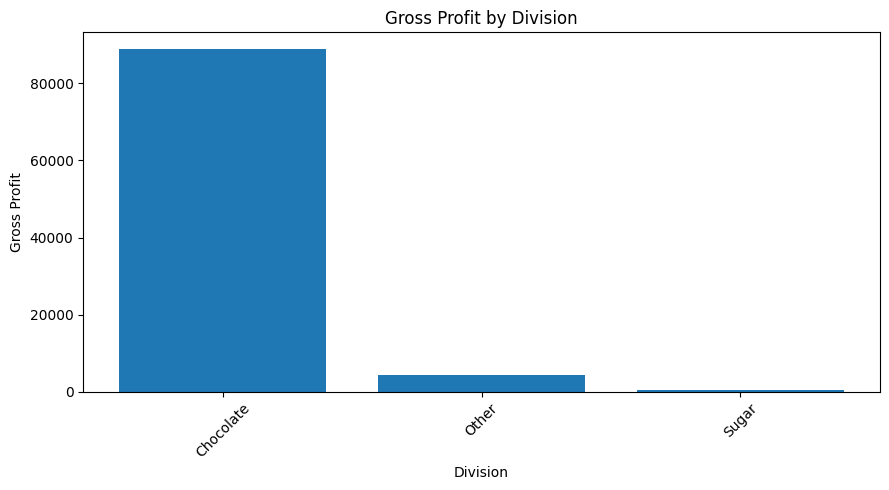

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(division_data["Division"], division_data["Gross Profit"])
plt.title("Gross Profit by Division")
plt.xlabel("Division")
plt.ylabel("Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Customers by Gross Profit
 Customer ID  Sales  Gross Profit   Cost  Total Orders  Profit Margin (%)
      131807 454.40        256.60 197.80            15          56.470070
      115238 380.50        249.30 131.20            15          65.519054
      122336 352.20        193.44 158.76             3          54.923339
      164756 304.14        166.42 137.72             5          54.718222
      139675 202.00        134.40  67.60            10          66.534653
      151799 197.60        132.52  65.08             6          67.064777
      124163 247.35        127.95 119.40             4          51.728320
      100111 182.41        125.93  56.48             5          69.036785
      164770 232.40        122.50 109.90             2          52.710843
      119508 177.14        122.34  54.80            10          69.064017


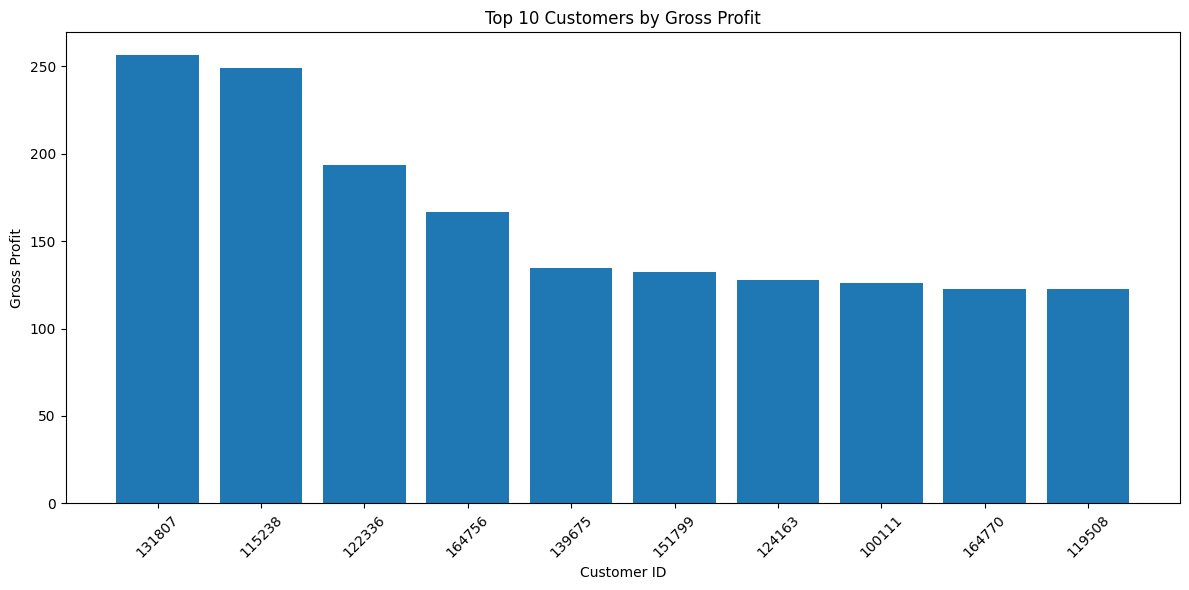

In [ ]:
import matplotlib.pyplot as plt

customer_data = df.groupby("Customer ID", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Order ID": "nunique"
})

customer_data = customer_data.rename(
    columns={"Order ID": "Total Orders"}
)

customer_data["Profit Margin (%)"] = (
    customer_data["Gross Profit"] /
    customer_data["Sales"].replace(0, float("nan")) * 100
)

top_customers = customer_data.nlargest(10, "Gross Profit")

print("Top 10 Customers by Gross Profit")
print(top_customers.to_string(index=False))

plt.figure(figsize=(12, 6))
plt.bar(
    top_customers["Customer ID"].astype(str),
    top_customers["Gross Profit"]
)
plt.title("Top 10 Customers by Gross Profit")
plt.xlabel("Customer ID")
plt.ylabel("Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
product_data = df.groupby(
    ["Product ID", "Product Name"], as_index=False
).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
})

product_data["Profit Margin (%)"] = (
    product_data["Gross Profit"] /
    product_data["Sales"].replace(0, float("nan")) * 100
)

low_margin = product_data[
    product_data["Sales"] > 0
].sort_values("Profit Margin (%)").head(10)

print("10 Lowest-Margin Products")
print(low_margin.to_string(index=False))

10 Lowest-Margin Products
   Product ID                      Product Name    Sales  Gross Profit    Cost  Units  Profit Margin (%)
OTH-KAZ-38000                         Kazookles  1205.75         92.75 1113.00    371           7.692308
SUG-FUN-75000                           Fun Dip    12.00          4.80    7.20      8          40.000000
SUG-NER-92000                             Nerds    15.00          7.00    8.00     10          46.666667
SUG-SWE-91000                         SweeTARTS    61.50         28.70   32.80     41          46.666667
OTH-LIC-15000                Lickable Wallpaper  7860.00       3930.00 3930.00    393          50.000000
OTH-GUM-21000                         Wonka Gum   597.50        310.70  286.80    478          52.000000
OTH-FIZ-56000              Fizzy Lifting Drinks    78.75         47.25   31.50     21          60.000000
SUG-LAF-25000                       Laffy Taffy    53.73         33.48   20.25     27          62.311558
CHO-MIL-31000        Wonka Ba

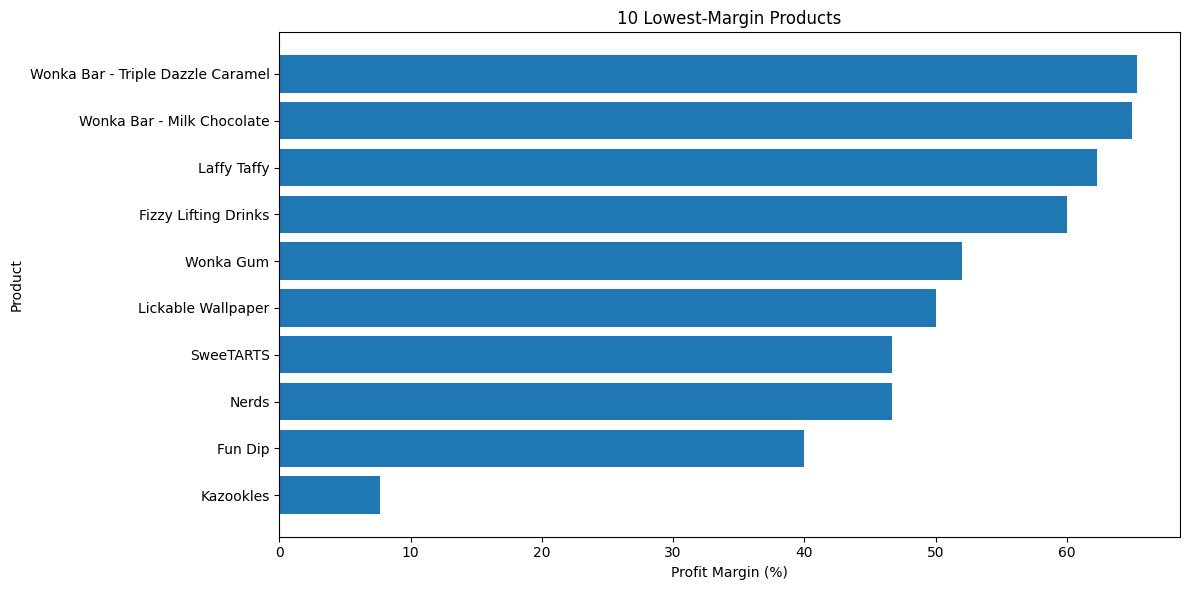

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.barh(
    low_margin["Product Name"],
    low_margin["Profit Margin (%)"]
)
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product")
plt.title("10 Lowest-Margin Products")
plt.tight_layout()
plt.show()

In [ ]:
total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_cost = df["Cost"].sum()
total_units = df["Units"].sum()
total_orders = df["Order ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

print("Total Sales:", round(total_sales, 2))
print("Total Gross Profit:", round(total_profit, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Units Sold:", total_units)
print("Total Orders:", total_orders)
print("Overall Profit Margin (%):", round(profit_margin, 2))

Total Sales: 141783.63
Total Gross Profit: 93442.8
Total Cost: 48340.83
Total Units Sold: 38654
Total Orders: 8549
Overall Profit Margin (%): 65.91


In [ ]:
df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Gross Profit"] = pd.to_numeric(df["Gross Profit"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum"
})

print(monthly_data.head())

     Month    Sales  Gross Profit
0  2024-01  2093.90       1366.14
1  2024-02  1379.87        908.59
2  2024-03  4138.90       2671.16
3  2024-04  3988.22       2612.81
4  2024-05  3951.52       2615.44


In [ ]:
print(monthly_data.columns.tolist())
print(monthly_data.head())

['Month', 'Sales', 'Gross Profit']
     Month    Sales  Gross Profit
0  2024-01  2093.90       1366.14
1  2024-02  1379.87        908.59
2  2024-03  4138.90       2671.16
3  2024-04  3988.22       2612.81
4  2024-05  3951.52       2615.44


In [ ]:
df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Gross Profit"] = pd.to_numeric(df["Gross Profit"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum"
})

print(monthly_data.head())

     Month    Sales  Gross Profit
0  2024-01  2093.90       1366.14
1  2024-02  1379.87        908.59
2  2024-03  4138.90       2671.16
3  2024-04  3988.22       2612.81
4  2024-05  3951.52       2615.44


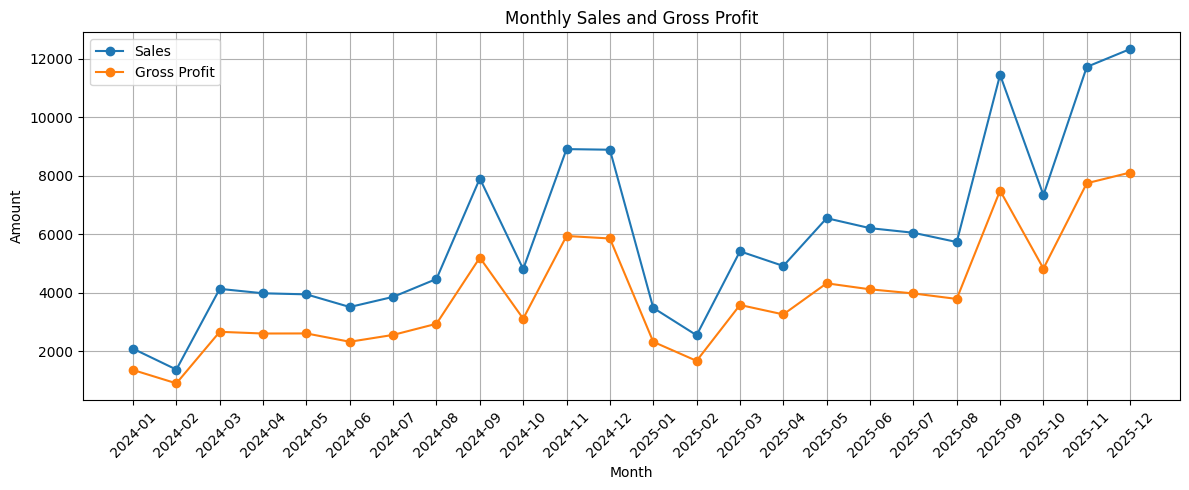

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.str.strip()

# Convert Order Date into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

# Create monthly data
df = df.dropna(subset=["Order Date"])
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

# Ensure numeric values
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

if "Gross Profit" in df.columns:
    df["Gross Profit"] = pd.to_numeric(
        df["Gross Profit"], errors="coerce"
    )
    monthly_data = df.groupby("Month", as_index=False)[
        ["Sales", "Gross Profit"]
    ].sum()
else:
    monthly_data = df.groupby("Month", as_index=False)[
        ["Sales"]
    ].sum()

# Plot graph
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_data["Month"],
    monthly_data["Sales"],
    marker="o",
    label="Sales"
)

if "Gross Profit" in monthly_data.columns:
    plt.plot(
        monthly_data["Month"],
        monthly_data["Gross Profit"],
        marker="o",
        label="Gross Profit"
    )

plt.xlabel("Month")
plt.ylabel("Amount")
plt.title("Monthly Sales and Gross Profit")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print(df.columns.tolist())
print(monthly_data.columns.tolist())
print(monthly_data.head())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Month']
['Month', 'Sales', 'Gross Profit']
     Month    Sales  Gross Profit
0  2024-01  2093.90       1366.14
1  2024-02  1379.87        908.59
2  2024-03  4138.90       2671.16
3  2024-04  3988.22       2612.81
4  2024-05  3951.52       2615.44


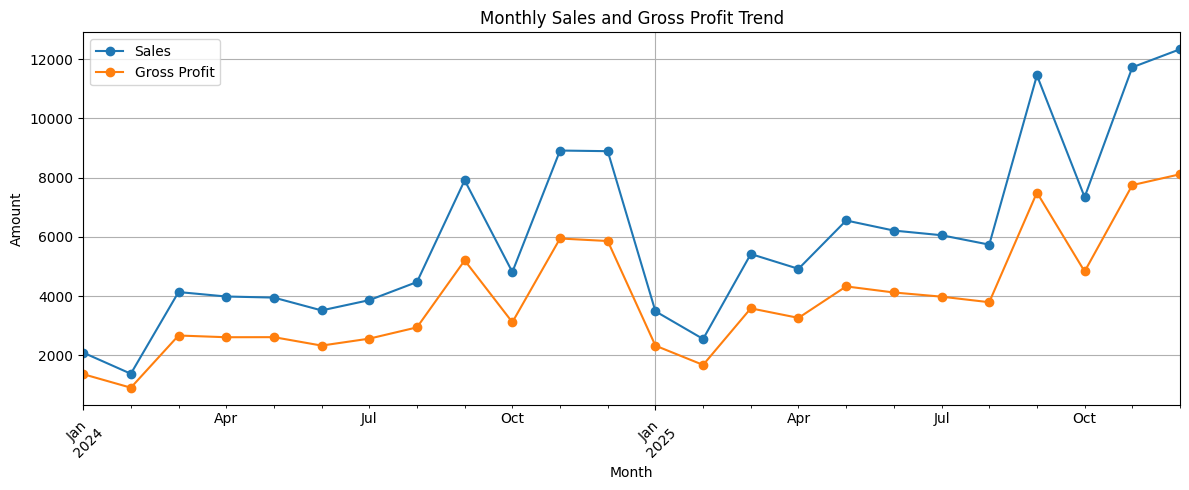

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M")

monthly_data = temp.groupby("Month")[["Sales", "Gross Profit"]].sum()

ax = monthly_data.plot(figsize=(12, 5), marker="o")

ax.set_title("Monthly Sales and Gross Profit Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

print("df exists:", "df" in globals())
print("monthly_data exists:", "monthly_data" in globals())


df exists: True
monthly_data exists: True


In [ ]:
print(monthly_data.columns.tolist())

['Sales', 'Gross Profit']


     Month    Sales  Gross Profit     Cost
0  2024-01  2093.90       1366.14   727.76
1  2024-02  1379.87        908.59   471.28
2  2024-03  4138.90       2671.16  1467.74
3  2024-04  3988.22       2612.81  1375.41
4  2024-05  3951.52       2615.44  1336.08


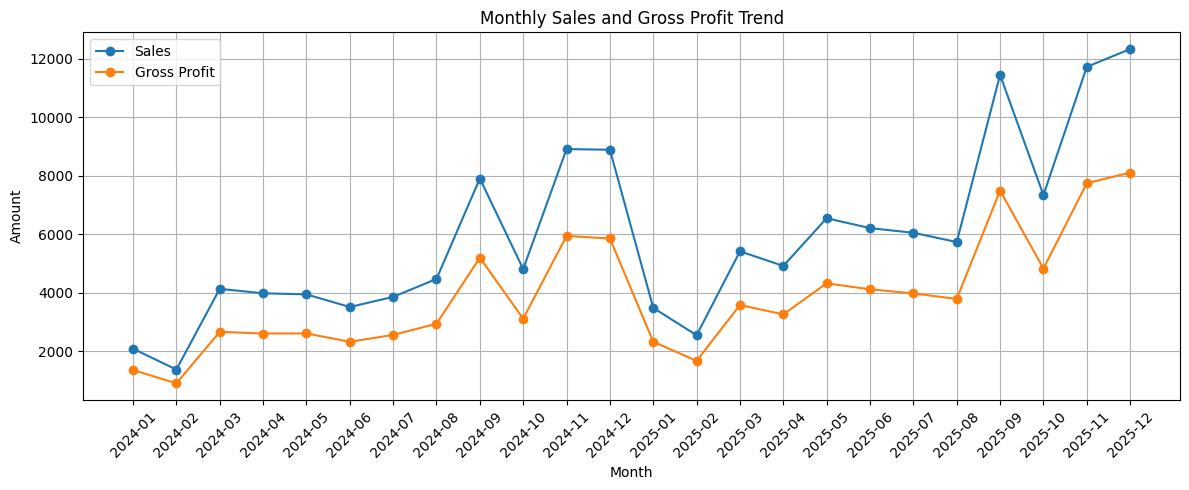

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly_data["Month"], monthly_data["Sales"], marker="o", label="Sales")
plt.plot(monthly_data["Month"], monthly_data["Gross Profit"], marker="o", label="Gross Profit")

plt.title("Monthly Sales and Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())


     Month    Sales  Gross Profit     Cost
0  2024-01  2093.90       1366.14   727.76
1  2024-02  1379.87        908.59   471.28
2  2024-03  4138.90       2671.16  1467.74
3  2024-04  3988.22       2612.81  1375.41
4  2024-05  3951.52       2615.44  1336.08


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month", observed=True).agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Cost=("Cost", "sum")
).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())


     Month    Sales  Gross_Profit     Cost
0  2024-01  2093.90       1366.14   727.76
1  2024-02  1379.87        908.59   471.28
2  2024-03  4138.90       2671.16  1467.74
3  2024-04  3988.22       2612.81  1375.41
4  2024-05  3951.52       2615.44  1336.08


In [ ]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDate range:")
print("Start:", df["Order Date"].min())
print("End:", df["Order Date"].max())

print("\nSales:", round(df["Sales"].sum(), 2))
print("Cost:", round(df["Cost"].sum(), 2))
print("Gross Profit:", round(df["Gross Profit"].sum(), 2))


Dataset shape: (10194, 19)

Missing values:
0

Date range:
Start: 2024-01-02 00:00:00
End: 2025-12-31 00:00:00

Sales: 141783.63
Cost: 48340.83
Gross Profit: 93442.8


In [ ]:

total_sales = df["Sales"].sum()
total_cost = df["Cost"].sum()
total_profit = df["Gross Profit"].sum()
total_orders = df["Order ID"].nunique()
total_products = df["Product Name"].nunique()
total_units = df["Units"].sum()

profit_margin = (
    total_profit / total_sales * 100 if total_sales != 0 else 0
)

print("Total Sales:", round(total_sales, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Gross Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Products:", total_products)
print("Total Units Sold:", total_units)
print("Overall Profit Margin:", round(profit_margin, 2), "%")


Total Sales: 141783.63
Total Cost: 48340.83
Total Gross Profit: 93442.8
Total Orders: 8549
Total Products: 15
Total Units Sold: 38654
Overall Profit Margin: 65.91 %


In [ ]:
print("Dataset columns:")
for col in df.columns:
    print(col)

Dataset columns:
Row ID
Order ID
Order Date
Ship Date
Ship Mode
Customer ID
Country/Region
City
State/Province
Postal Code
Division
Region
Product ID
Product Name
Sales
Units
Gross Profit
Cost
Month


In [ ]:

print("Dataset shape:", df.shape)

for col in df.columns:
    if any(word in col.lower() for word in
           ["factory", "latitude", "longitude", "product", "city", "state", "region"]):
        print(f"\n{col}")
        print(df[col].nunique(), "unique values")
        print(df[col].dropna().unique()[:10])


Dataset shape: (10194, 19)

Country/Region
2 unique values
['United States' 'Canada']

City
542 unique values
['Houston' 'Naperville' 'Philadelphia' 'Henderson' 'Athens' 'Los Angeles'
 'Huntsville' 'Laredo' 'Springfield' 'Dover']

State/Province
59 unique values
['Texas' 'Illinois' 'Pennsylvania' 'Kentucky' 'Georgia' 'California'
 'Virginia' 'Delaware' 'South Carolina' 'Ohio']

Region
4 unique values
['Interior' 'Atlantic' 'Gulf' 'Pacific']

Product ID
15 unique values
['CHO-MIL-31000' 'CHO-TRI-54000' 'CHO-NUT-13000' 'CHO-SCR-58000'
 'CHO-FUD-51000' 'OTH-GUM-21000' 'OTH-KAZ-38000' 'OTH-LIC-15000'
 'OTH-FIZ-56000' 'SUG-LAF-25000']

Product Name
15 unique values
['Wonka Bar - Milk Chocolate' 'Wonka Bar - Triple Dazzle Caramel'
 'Wonka Bar - Nutty Crunch Surprise' 'Wonka Bar -Scrumdiddlyumptious'
 'Wonka Bar - Fudge Mallows' 'Wonka Gum' 'Kazookles' 'Lickable Wallpaper'
 'Fizzy Lifting Drinks' 'Laffy Taffy']


In [ ]:

# Create product analysis
df.columns = df.columns.str.strip()

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"].replace(0, float("nan"))
) * 100

print("Product analysis created successfully!")
display(product_analysis.head())


Product analysis created successfully!


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
0,Everlasting Gobstopper,130.00,104.00,26.0,80.000000
1,Fizzy Lifting Drinks,78.75,47.25,31.5,60.000000
2,Fun Dip,12.00,4.80,7.2,40.000000
3,Hair Toffee,76.50,59.50,17.0,77.777778
4,Kazookles,1205.75,92.75,1113.0,7.692308


In [ ]:

top_products = product_analysis.sort_values(
    by="Gross Profit",
    ascending=False
)

display(top_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
13,Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,8517.30,69.444444
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,65.333333
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,64.923077
11,Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755.00,71.346705
9,Wonka Bar - Fudge Mallows,24890.40,16593.60,8296.80,66.666667
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
14,Wonka Gum,597.50,310.70,286.80,52.000000
0,Everlasting Gobstopper,130.00,104.00,26.00,80.000000
4,Kazookles,1205.75,92.75,1113.00,7.692308
3,Hair Toffee,76.50,59.50,17.00,77.777778


['Month', 'Sales', 'Gross Profit', 'Cost']
     Month    Sales  Gross Profit     Cost
0  2024-01  2093.90       1366.14   727.76
1  2024-02  1379.87        908.59   471.28
2  2024-03  4138.90       2671.16  1467.74
3  2024-04  3988.22       2612.81  1375.41
4  2024-05  3951.52       2615.44  1336.08


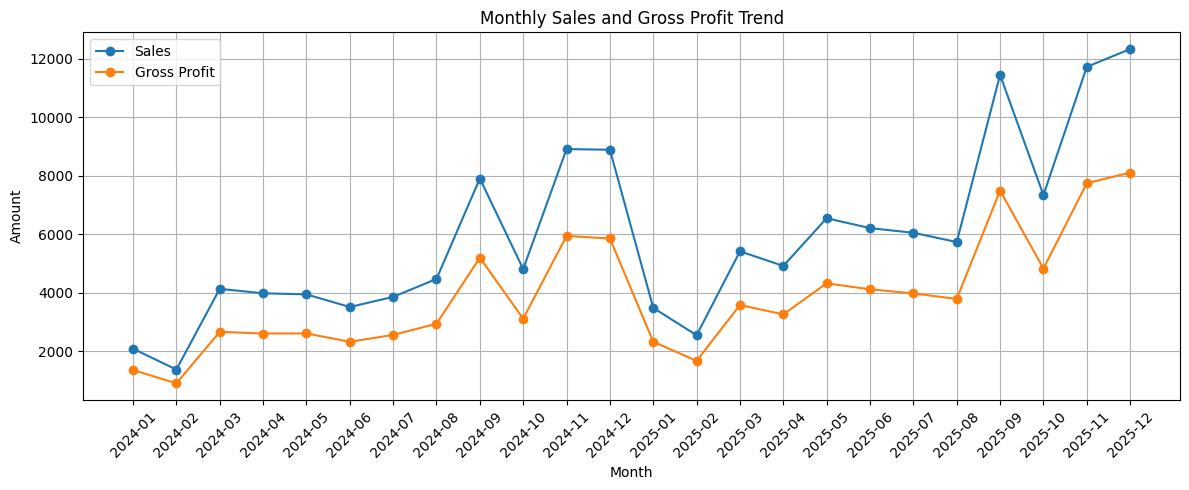

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

for col in ["Sales", "Gross Profit", "Cost"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
})

print(monthly_data.columns.tolist())
print(monthly_data.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly_data["Month"], monthly_data["Sales"],
         marker="o", label="Sales")
plt.plot(monthly_data["Month"], monthly_data["Gross Profit"],
         marker="o", label="Gross Profit")

plt.title("Monthly Sales and Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
for col in df.columns:
    if any(word in col.lower() for word in
           ["factory", "latitude", "longitude", "product", "location"]):
        print(col, ":", df[col].nunique(), "unique values")

Product ID : 15 unique values
Product Name : 15 unique values


In [ ]:
print("Top 10 Products")
display(top_products.head(10))

print("Bottom 10 Products")
display(product_analysis.sort_values(
    by="Gross Profit",
    ascending=True
).head(10))

Top 10 Products


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
13,Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,8517.30,69.444444
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,65.333333
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,64.923077
11,Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755.00,71.346705
9,Wonka Bar - Fudge Mallows,24890.40,16593.60,8296.80,66.666667
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
14,Wonka Gum,597.50,310.70,286.80,52.000000
0,Everlasting Gobstopper,130.00,104.00,26.00,80.000000
4,Kazookles,1205.75,92.75,1113.00,7.692308
3,Hair Toffee,76.50,59.50,17.00,77.777778


Bottom 10 Products


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
2,Fun Dip,12.00,4.80,7.20,40.000000
7,Nerds,15.00,7.00,8.00,46.666667
8,SweeTARTS,61.50,28.70,32.80,46.666667
5,Laffy Taffy,53.73,33.48,20.25,62.311558
1,Fizzy Lifting Drinks,78.75,47.25,31.50,60.000000
3,Hair Toffee,76.50,59.50,17.00,77.777778
4,Kazookles,1205.75,92.75,1113.00,7.692308
0,Everlasting Gobstopper,130.00,104.00,26.00,80.000000
14,Wonka Gum,597.50,310.70,286.80,52.000000
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000


In [ ]:

numerical_data = df[
    ["Sales", "Units", "Gross Profit", "Cost"]
]

correlation = numerical_data.corr()

display(correlation)


,Sales,Units,Gross Profit,Cost
Sales,1.000000,0.729347,0.976404,0.958986
Units,0.729347,1.000000,0.815820,0.563344
Gross Profit,0.976404,0.815820,1.000000,0.875144
Cost,0.958986,0.563344,0.875144,1.000000


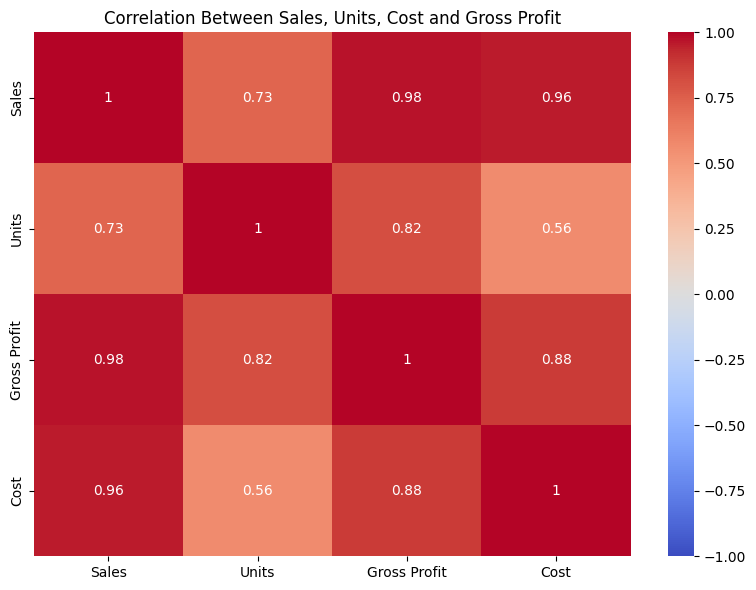

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Sales, Units, Cost and Gross Profit")
plt.tight_layout()
plt.show()


In [ ]:

shipping_analysis = df.groupby("Ship Mode").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Order ID": "nunique"
}).reset_index()

shipping_analysis = shipping_analysis.rename(
    columns={"Order ID": "Number of Orders"}
)

shipping_analysis["Profit Margin (%)"] = (
    shipping_analysis["Gross Profit"] /
    shipping_analysis["Sales"]
) * 100

display(shipping_analysis)


,Ship Mode,Sales,Gross Profit,Cost,Number of Orders,Profit Margin (%)
0,First Class,21319.39,14011.09,7308.30,1312,65.719939
1,Same Day,7113.67,4700.73,2412.94,442,66.080237
2,Second Class,27860.22,18306.52,9553.70,1653,65.708455
3,Standard Class,85490.35,56424.46,29065.89,5142,66.000970


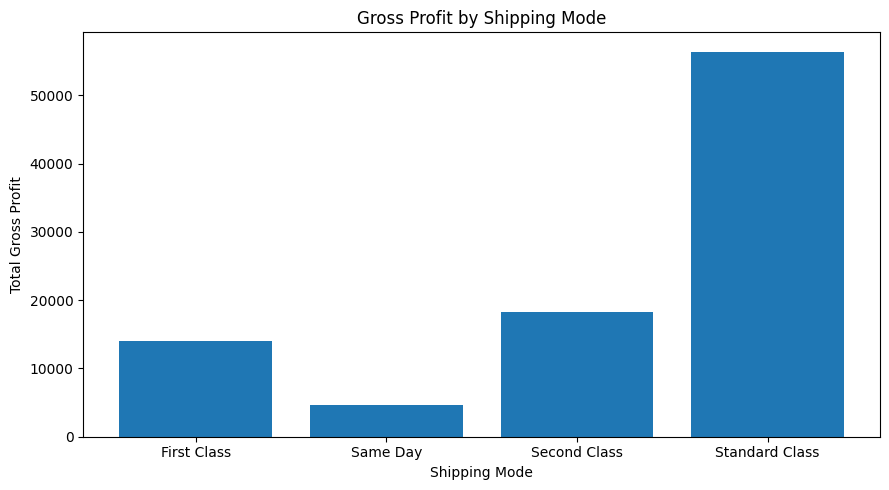

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    shipping_analysis["Ship Mode"],
    shipping_analysis["Gross Profit"]
)
plt.xlabel("Shipping Mode")
plt.ylabel("Total Gross Profit")
plt.title("Gross Profit by Shipping Mode")
plt.tight_layout()
plt.show()


In [ ]:

region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

region_analysis["Profit Margin (%)"] = (
    region_analysis["Gross Profit"] /
    region_analysis["Sales"]
) * 100

region_analysis = region_analysis.sort_values(
    by="Gross Profit", ascending=False
)

display(region_analysis)


,Region,Sales,Gross Profit,Cost,Profit Margin (%)
3,Pacific,46301.53,30485.94,15815.59,65.842187
0,Atlantic,41197.24,26973.70,14223.54,65.474532
2,Interior,32037.60,21282.49,10755.11,66.429726
1,Gulf,22247.26,14700.67,7546.59,66.078564


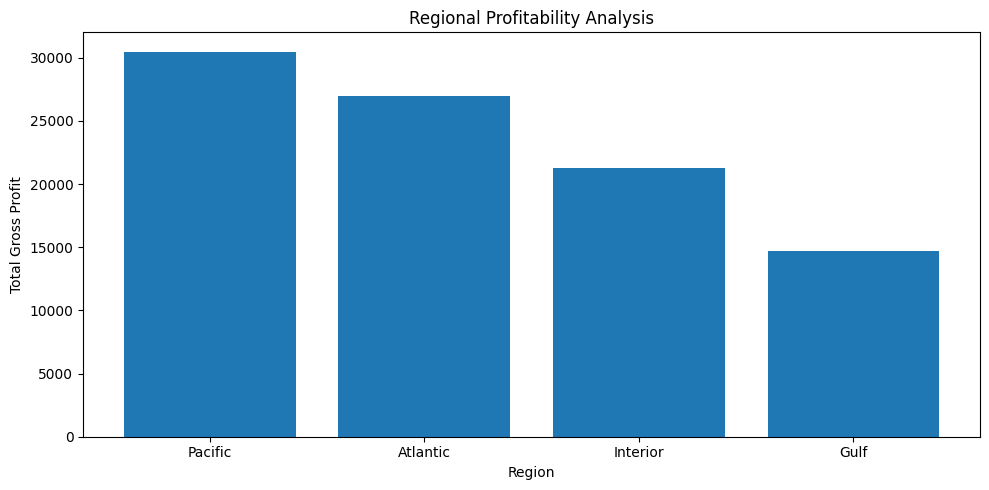

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(region_analysis["Region"], region_analysis["Gross Profit"])
plt.xlabel("Region")
plt.ylabel("Total Gross Profit")
plt.title("Regional Profitability Analysis")
plt.tight_layout()
plt.show()


In [ ]:

df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)

df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Sales"].sum().reset_index()

display(monthly_sales)


,Month,Sales
0,2024-01,2093.90
1,2024-02,1379.87
2,2024-03,4138.90
3,2024-04,3988.22
4,2024-05,3951.52
5,2024-06,3518.76
6,2024-07,3865.38
7,2024-08,4477.65
8,2024-09,7912.10
9,2024-10,4815.98


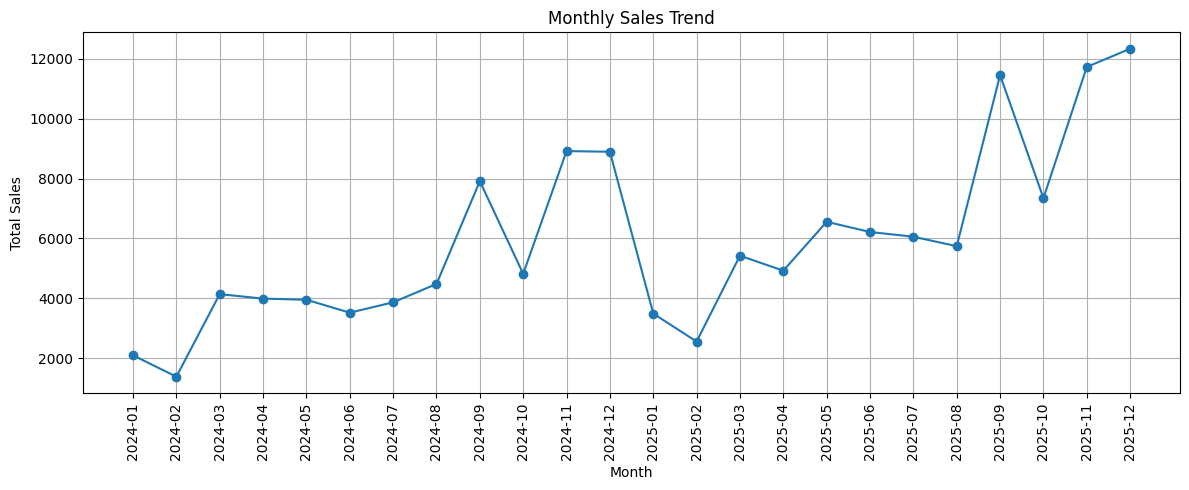

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month"], monthly_sales["Sales"], marker="o")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Create division analysis
df.columns = df.columns.str.strip()

division_analysis = df.groupby("Division", as_index=False).agg({
    "Gross Profit": "sum"
})

display(division_analysis)


,Division,Gross Profit
0,Chocolate,88824.62
1,Other,4333.45
2,Sugar,284.73


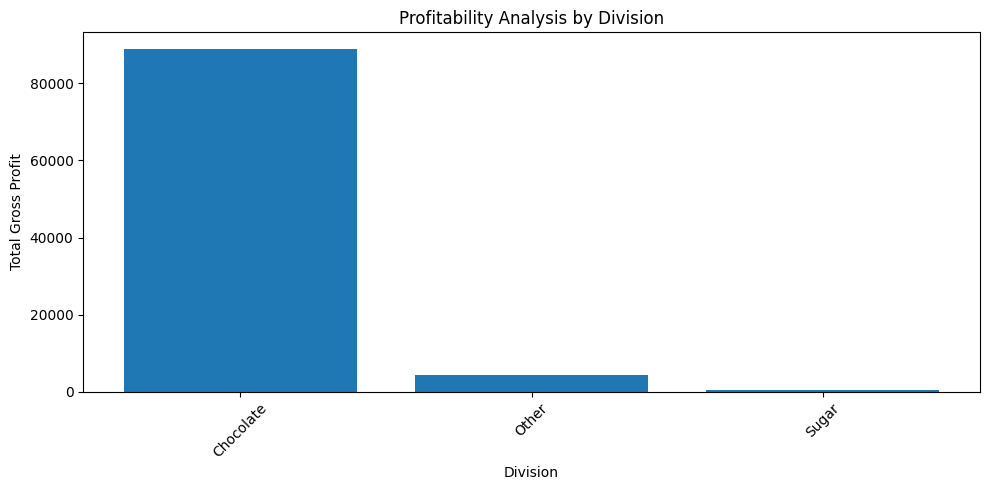

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(
    division_analysis["Division"],
    division_analysis["Gross Profit"]
)
plt.xlabel("Division")
plt.ylabel("Total Gross Profit")
plt.title("Profitability Analysis by Division")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

division_analysis = df.groupby("Division").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

division_analysis["Profit Margin (%)"] = (
    division_analysis["Gross Profit"] /
    division_analysis["Sales"]
) * 100

division_analysis = division_analysis.sort_values(
    by="Gross Profit", ascending=False
)

display(division_analysis)


,Division,Sales,Gross Profit,Cost,Profit Margin (%)
0,Chocolate,131692.90,88824.62,42868.28,67.448298
1,Other,9663.25,4333.45,5329.80,44.844643
2,Sugar,427.48,284.73,142.75,66.606625


In [ ]:

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] / product_analysis["Sales"]
) * 100

print("Product analysis created successfully!")
display(product_analysis.head())


Product analysis created successfully!


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
0,Everlasting Gobstopper,130.00,104.00,26.0,80.000000
1,Fizzy Lifting Drinks,78.75,47.25,31.5,60.000000
2,Fun Dip,12.00,4.80,7.2,40.000000
3,Hair Toffee,76.50,59.50,17.0,77.777778
4,Kazookles,1205.75,92.75,1113.0,7.692308


In [ ]:

product_margin = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_margin["Profit Margin (%)"] = (
    product_margin["Gross Profit"] / product_margin["Sales"]
) * 100

product_margin = product_margin.sort_values(
    by="Profit Margin (%)", ascending=True
)

product_margin.head(10)


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
4,Kazookles,1205.75,92.75,1113.00,7.692308
2,Fun Dip,12.00,4.80,7.20,40.000000
7,Nerds,15.00,7.00,8.00,46.666667
8,SweeTARTS,61.50,28.70,32.80,46.666667
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
14,Wonka Gum,597.50,310.70,286.80,52.000000
1,Fizzy Lifting Drinks,78.75,47.25,31.50,60.000000
5,Laffy Taffy,53.73,33.48,20.25,62.311558
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,64.923077
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,65.333333


In [ ]:

top_products = df.groupby("Product Name")["Gross Profit"].sum().sort_values(ascending=False).reset_index()

top_products.head(10)


,Product Name,Gross Profit
0,Wonka Bar -Scrumdiddlyumptious,19357.50
1,Wonka Bar - Triple Dazzle Caramel,18610.20
2,Wonka Bar - Milk Chocolate,17443.37
3,Wonka Bar - Nutty Crunch Surprise,16819.95
4,Wonka Bar - Fudge Mallows,16593.60
5,Lickable Wallpaper,3930.00
6,Wonka Gum,310.70
7,Everlasting Gobstopper,104.00
8,Kazookles,92.75
9,Hair Toffee,59.50


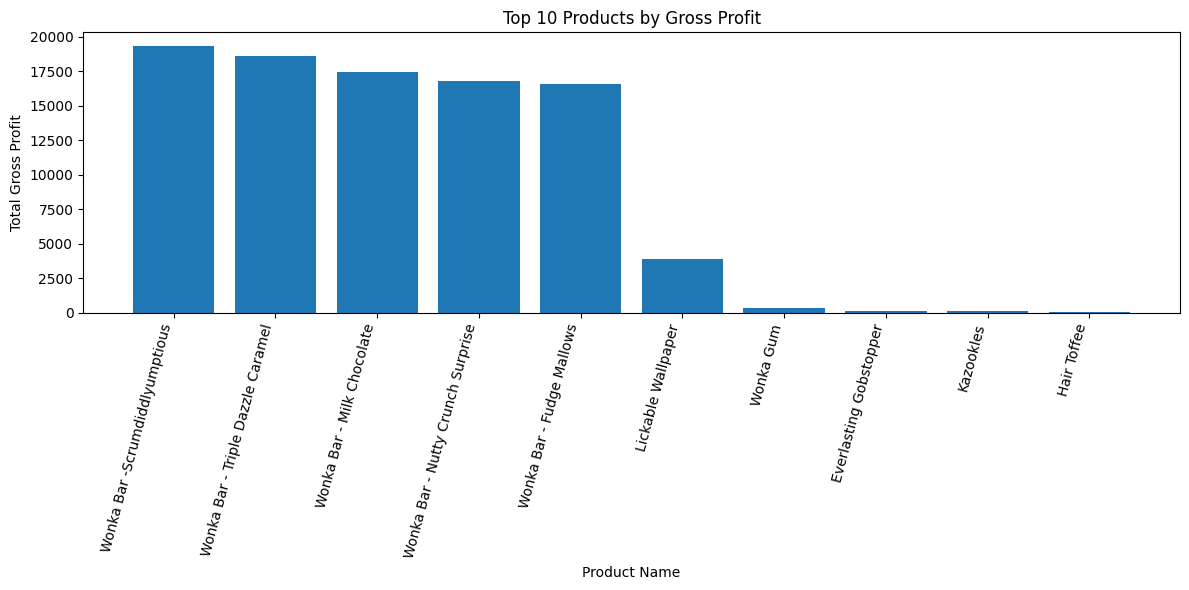

In [ ]:

import matplotlib.pyplot as plt

top10 = top_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10["Product Name"], top10["Gross Profit"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Total Gross Profit")
plt.title("Top 10 Products by Gross Profit")
plt.tight_layout()
plt.show()


In [ ]:

region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
}).reset_index()

region_analysis["Profit Margin (%)"] = (
    region_analysis["Gross Profit"] /
    region_analysis["Sales"]
) * 100

display(region_analysis)


,Region,Sales,Gross Profit,Cost,Units,Profit Margin (%)
0,Atlantic,41197.24,26973.70,14223.54,11159,65.474532
1,Gulf,22247.26,14700.67,7546.59,6209,66.078564
2,Interior,32037.60,21282.49,10755.11,8820,66.429726
3,Pacific,46301.53,30485.94,15815.59,12466,65.842187


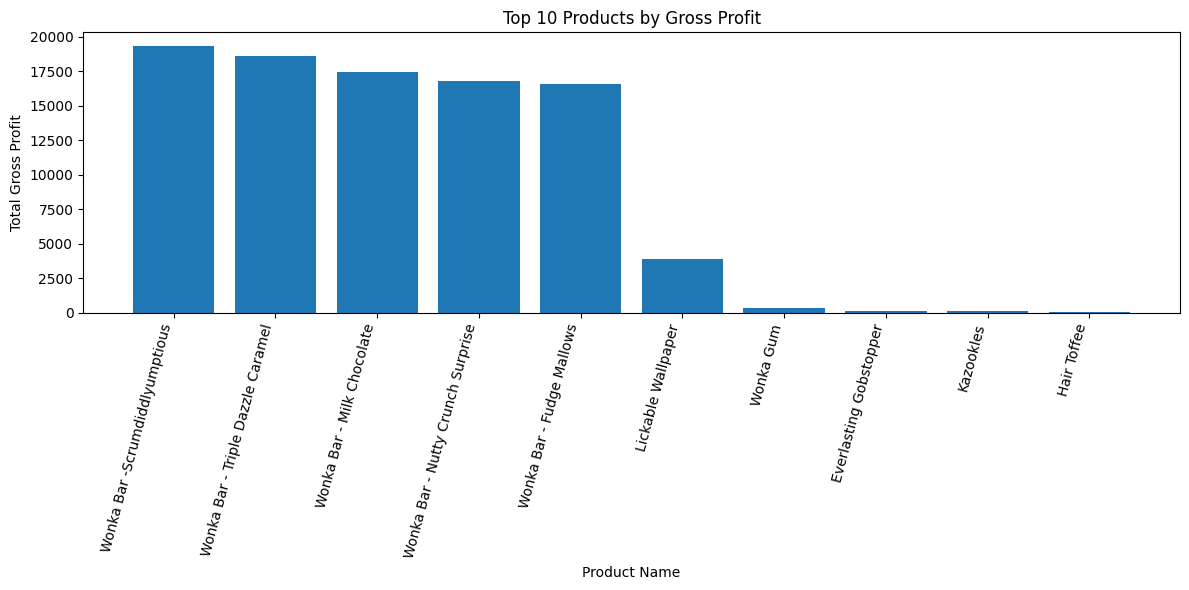

In [ ]:

import matplotlib.pyplot as plt

top10 = top_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10["Product Name"], top10["Gross Profit"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Total Gross Profit")
plt.title("Top 10 Products by Gross Profit")
plt.tight_layout()
plt.show()


In [ ]:

low_margin_products = product_analysis.sort_values(
    by="Profit Margin (%)",
    ascending=True
)

display(low_margin_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
4,Kazookles,1205.75,92.75,1113.00,7.692308
2,Fun Dip,12.00,4.80,7.20,40.000000
7,Nerds,15.00,7.00,8.00,46.666667
8,SweeTARTS,61.50,28.70,32.80,46.666667
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
14,Wonka Gum,597.50,310.70,286.80,52.000000
1,Fizzy Lifting Drinks,78.75,47.25,31.50,60.000000
5,Laffy Taffy,53.73,33.48,20.25,62.311558
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,64.923077
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,65.333333


In [ ]:

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"]
) * 100


In [ ]:

low_margin_products = product_analysis.sort_values(
    by="Profit Margin (%)",
    ascending=True
)

display(low_margin_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
4,Kazookles,1205.75,92.75,1113.00,7.692308
2,Fun Dip,12.00,4.80,7.20,40.000000
7,Nerds,15.00,7.00,8.00,46.666667
8,SweeTARTS,61.50,28.70,32.80,46.666667
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
14,Wonka Gum,597.50,310.70,286.80,52.000000
1,Fizzy Lifting Drinks,78.75,47.25,31.50,60.000000
5,Laffy Taffy,53.73,33.48,20.25,62.311558
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,64.923077
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,65.333333


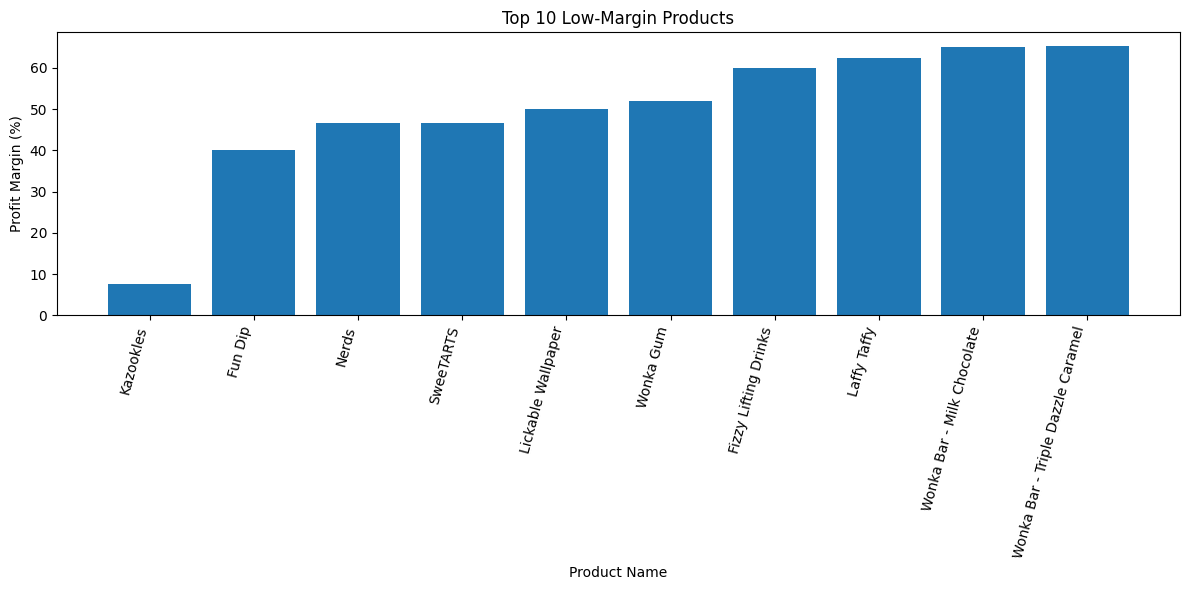

In [ ]:

import matplotlib.pyplot as plt

low10 = low_margin_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(low10["Product Name"], low10["Profit Margin (%)"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Profit Margin (%)")
plt.title("Top 10 Low-Margin Products")
plt.tight_layout()
plt.show()


In [ ]:

top_products = product_analysis.sort_values(
    by="Gross Profit",
    ascending=False
)

display(top_products.head(10))


,Product Name,Sales,Gross Profit,Cost,Profit Margin (%)
13,Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,8517.30,69.444444
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,65.333333
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,64.923077
11,Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755.00,71.346705
9,Wonka Bar - Fudge Mallows,24890.40,16593.60,8296.80,66.666667
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
14,Wonka Gum,597.50,310.70,286.80,52.000000
0,Everlasting Gobstopper,130.00,104.00,26.00,80.000000
4,Kazookles,1205.75,92.75,1113.00,7.692308
3,Hair Toffee,76.50,59.50,17.00,77.777778


In [ ]:

import pandas as pd

df["Profit Margin (%)"] = (
    df["Gross Profit"] / df["Sales"]
) * 100

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"]
) * 100

print(product_analysis.head(10))


                Product Name     Sales  Gross Profit     Cost  Units  \
0     Everlasting Gobstopper    130.00        104.00    26.00     13   
1       Fizzy Lifting Drinks     78.75         47.25    31.50     21   
2                    Fun Dip     12.00          4.80     7.20      8   
3                Hair Toffee     76.50         59.50    17.00     17   
4                  Kazookles   1205.75         92.75  1113.00    371   
5                Laffy Taffy     53.73         33.48    20.25     27   
6         Lickable Wallpaper   7860.00       3930.00  3930.00    393   
7                      Nerds     15.00          7.00     8.00     10   
8                  SweeTARTS     61.50         28.70    32.80     41   
9  Wonka Bar - Fudge Mallows  24890.40      16593.60  8296.80   6914   

   Profit Margin (%)  
0          80.000000  
1          60.000000  
2          40.000000  
3          77.777778  
4           7.692308  
5          62.311558  
6          50.000000  
7          46.666667  


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df.describe()

,Row ID,Order Date,Customer ID,Sales,Units,Gross Profit,Cost,Profit Margin (%)
count,10194.000000,10194,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-03-13 03:08:26.415538176,134468.961154,13.908537,3.791838,9.166451,4.742087,66.514045
min,1.000000,2024-01-02 00:00:00,100006.000000,1.250000,1.000000,0.250000,0.600000,7.692308
25%,2549.250000,2024-09-28 00:00:00,117212.000000,7.200000,2.000000,4.900000,2.400000,65.333333
50%,5097.500000,2025-04-06 12:00:00,133550.000000,10.800000,3.000000,7.470000,3.600000,66.666667
75%,7645.750000,2025-09-16 00:00:00,152051.000000,18.000000,5.000000,12.250000,5.700000,69.444444
max,10194.000000,2025-12-31 00:00:00,192314.000000,260.000000,14.000000,130.000000,130.000000,80.000000
std,2942.898656,NaN,20231.483007,11.341020,2.228317,6.643740,5.061647,6.721012


In [ ]:
display(df.head(10))

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Month,Profit Margin (%)
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,2024-01,64.923077
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,2024-01,65.333333
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,2024-01,71.346705
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,2024-01,69.444444
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,2024-01,65.333333
5,6,US-2021-167199-CHO-SCR-58000,2024-01-06,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,32.40,9,22.50,9.90,2024-01,69.444444
6,7,US-2021-167199-CHO-TRI-54000,2024-01-06,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,2024-01,65.333333
7,8,US-2021-106054-CHO-MIL-31000,2024-01-06,30-06-2026,First Class,106054,United States,Athens,Georgia,30605,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42,2024-01,64.923077
8,9,US-2021-167199-CHO-NUT-13000,2024-01-06,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00,2024-01,71.346705
9,10,US-2021-167199-CHO-MIL-31000,2024-01-06,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,13.00,4,8.44,4.56,2024-01,64.923077


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (10194, 20)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Month', 'Profit Margin (%)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Row ID             10194 non-null  int64         
 1   Order ID           10194 non-null  object        
 2   Order Date         10194 non-null  datetime64[ns]
 3   Ship Date          10194 non-null  object        
 4   Ship Mode          10194 non-null  object        
 5   Customer ID        10194 non-null  int64         
 6   Country/Region     10194 non-null  object        
 7   City               10194 non-null  object        
 8   State/Provi

In [ ]:

print("Duplicate rows:", df.duplicated().sum())

print("\nSales summary:")
print(df["Sales"].describe())

print("\nGross Profit summary:")
print(df["Gross Profit"].describe())

print("\nCost summary:")
print(df["Cost"].describe())

print("\nInvalid values:")
print("Sales <= 0:", (df["Sales"] <= 0).sum())
print("Cost < 0:", (df["Cost"] < 0).sum())


Duplicate rows: 0

Sales summary:
count    10194.000000
mean        13.908537
std         11.341020
min          1.250000
25%          7.200000
50%         10.800000
75%         18.000000
max        260.000000
Name: Sales, dtype: float64

Gross Profit summary:
count    10194.000000
mean         9.166451
std          6.643740
min          0.250000
25%          4.900000
50%          7.470000
75%         12.250000
max        130.000000
Name: Gross Profit, dtype: float64

Cost summary:
count    10194.000000
mean         4.742087
std          5.061647
min          0.600000
25%          2.400000
50%          3.600000
75%          5.700000
max        130.000000
Name: Cost, dtype: float64

Invalid values:
Sales <= 0: 0
Cost < 0: 0


In [ ]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (10194, 20)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Month', 'Profit Margin (%)']

Missing values:
Row ID               0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
Customer ID          0
Country/Region       0
City                 0
State/Province       0
Postal Code          0
Division             0
Region               0
Product ID           0
Product Name         0
Sales                0
Units                0
Gross Profit         0
Cost                 0
Month                0
Profit Margin (%)    0
dtype: int64

Data types:
Row ID                        int64
Order ID                     object
Order Date           datetime64[ns]
Ship Date                    object
Ship Mode                    object
Customer ID   

## Final Conclusion

The Nassau Candy Distributor project analyzed sales, costs, gross profit, product performance, regional profitability, shipping modes, and monthly trends.

Data visualizations and exploratory analysis helped identify patterns in product and business profitability. A Random Forest Regressor was also evaluated to understand how selected features relate to Gross Profit.

The model comparison showed that Sales, Units, and Cost produced near-perfect evaluation scores. However, since Gross Profit is calculated as Sales minus Cost, these scores do not demonstrate independent forecasting ability. The Units-only model provided a useful baseline for comparison.

The project demonstrates how data analysis, visualization, and machine learning can support business understanding and profitability analysis. Future improvements could include forecasting future sales and profitability using historical data available before the prediction period.